<a href="https://colab.research.google.com/github/phlapapon-kulto/Pandas_Review_673020626-9/blob/main/SC663402_Pandas_Review_673020626_9_%E0%B8%9B%E0%B8%A3%E0%B8%B0%E0%B8%A0%E0%B8%B2%E0%B8%9E%E0%B8%A3_%E0%B8%81%E0%B8%B8%E0%B8%A5%E0%B9%82%E0%B8%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-thai-tlwg is already the newest version (1:0.7.3-1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!


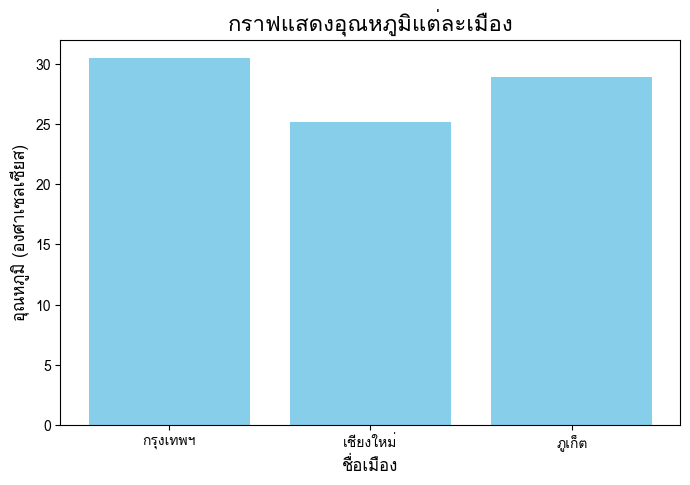

In [1]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [2]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [3]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


In [4]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


In [5]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


In [6]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


In [7]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


In [8]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


**อธิบาย:**

  * **1.1** ["a"] เลือกด้วย ชื่อ index, .iloc[0] เลือกด้วย ตำแหน่ง

  * **1.2** df["city"] → Series, df[["city"]] → DataFrame

  * **1.3** .loc[0:3] รวม 0–3 แต่ .iloc[0:3] ได้ 0–2

  * **1.4** count() นับเฉพาะค่าที่ไม่ว่าง, size() นับทุกแถว

  * **1.5** ["temperature_c"] → ผลเป็น Series, [["temperature_c"]] → DataFrame

  * **1.6** Pandas a+b จับคู่ตาม index, NumPy จับคู่ตาม ตำแหน่ง

ต้องการเลือกตามชื่อ → .loc

ต้องการเลือกตามตำแหน่ง → .iloc

ต้องการ 1 คอลัมน์ → ["col"] (Series)

ต้องการตาราง → [["col"]] (DataFrame)

นับค่าที่ไม่ว่าง → count()

นับจำนวนแถว → size()

คำนวณให้ตรงตาม index → Pandas

คำนวณตามตำแหน่ง → NumPy

---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [9]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [10]:
# คำตอบข้อ 2.1
rain_by_city = df.set_index("city")["rainfall_mm"]
print(rain_by_city.head(3))

print("เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก:")
print(rain_by_city.nlargest(3))

print("สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด:")
print((rain_by_city / rain_by_city.sum() * 100).round(2))

print("จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง:")
print((rain_by_city > rain_by_city.mean()).sum())

city
New York       6.3
Tokyo          0.0
Los Angeles    1.2
Name: rainfall_mm, dtype: float64
เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก:
city
Singapore    17.6
Lagos        17.3
Singapore    17.2
Name: rainfall_mm, dtype: float64
สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด:
city
New York       0.08
Tokyo          0.00
Los Angeles    0.01
Mumbai         0.10
Cape Town      0.00
               ... 
Mexico City    0.09
Nairobi        0.04
Nairobi        0.11
Toronto        0.11
Paris          0.08
Name: rainfall_mm, Length: 2075, dtype: float64
จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง:
889


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [11]:
# คำตอบข้อ 2.2
city_profile = df.groupby('city').agg(
    country=('country', 'first'),
    region=('region', 'first'),
    n_records=('record_id', 'count'),
    avg_temp=('temperature_c', 'mean'),
    total_rain=('rainfall_mm', 'sum')
).reset_index() # .reset_index() to make 'city' a regular column
city_profile

,city,country,region,n_records,avg_temp,total_rain
0,Auckland,New Zealand,Oceania,90,17.804444,351.9
1,Bangkok,Thailand,Asia,91,32.453846,685.6
2,Beijing,China,Asia,90,15.598876,250.1
3,Berlin,Germany,Europe,90,12.383146,268.4
4,Buenos Aires,Argentina,South America,90,19.171910,305.1
5,Cairo,Egypt,Africa,91,26.089888,123.0
6,Cape Town,South Africa,Africa,90,30.162921,239.3
7,Chiang Mai,Thailand,Asia,91,29.680220,435.6
8,Lagos,Nigeria,Africa,90,29.494253,652.8
9,Lima,Peru,South America,90,21.490000,180.3


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [12]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [13]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [14]:
# คำตอบข้อ 3.1
df_ww = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["date","city","temperature_c","region","humidity_pct","rainfall_mm"],
    na_values=[999,-999],
    dtype={"city": "category", "region": "category"},
    index_col="city",
    parse_dates=["date"],
    nrows=5,
)
print(df_ww.dtypes)
df_ww.info()

date             datetime64[ns]
region                 category
temperature_c           float64
humidity_pct            float64
rainfall_mm             float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
CategoricalIndex: 5 entries, New York to Cape Town
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           5 non-null      datetime64[ns]
 1   region         5 non-null      category      
 2   temperature_c  5 non-null      float64       
 3   humidity_pct   5 non-null      float64       
 4   rainfall_mm    5 non-null      float64       
dtypes: category(1), datetime64[ns](1), float64(3)
memory usage: 514.0 bytes


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [15]:
# คำตอบข้อ 3.2
original_total_memory = df.memory_usage(deep=True).sum()

optimized_total_memory = df_ww.memory_usage(deep=True).sum()

# Calculate percentage reduction
percentage_reduction = ((original_total_memory - optimized_total_memory) / original_total_memory) * 100

print(f"หน่วยความจำรวมของตารางปกติ (df): {original_total_memory} bytes")
print(f"หน่วยความจำรวมของตารางที่นำเข้าตามโจทย์ 3.1 (df_ww): {optimized_total_memory} bytes")
print(f"ร้อยละที่ลดลง: {percentage_reduction:.2f}%")


# Memory usage of original relevant columns
mem_original_date = df['date'].memory_usage(deep=True)
mem_original_city = df['city'].memory_usage(deep=True)
mem_original_region = df['region'].memory_usage(deep=True)

# Memory usage of optimized relevant columns
mem_optimized_date = df_ww['date'].memory_usage(deep=True)
mem_optimized_city_index = df_ww.index.memory_usage(deep=True) # city is index
mem_optimized_region = df_ww['region'].memory_usage(deep=True)

print("\nเปรียบเทียบหน่วยความจำรายคอลัมน์ (bytes):")
print(f"  คอลัมน์ 'date': เดิม {mem_original_date}, ใหม่ {mem_optimized_date}. ลดลง: {mem_original_date - mem_optimized_date}")
print(f"  คอลัมน์ 'city' (และ Index): เดิม {mem_original_city}, ใหม่ (index) {mem_optimized_city_index}. ลดลง: {mem_original_city - mem_optimized_city_index}")
print(f"  คอลัมน์ 'region': เดิม {mem_original_region}, ใหม่ {mem_optimized_region}. ลดลง: {mem_original_region - mem_optimized_region}")

print(f"คอลัมน์ที่มีผลต่อการลดลงมากที่สุดคือ: date ")

หน่วยความจำรวมของตารางปกติ (df): 571645 bytes
หน่วยความจำรวมของตารางที่นำเข้าตามโจทย์ 3.1 (df_ww): 904 bytes
ร้อยละที่ลดลง: 99.84%

เปรียบเทียบหน่วยความจำรายคอลัมน์ (bytes):
  คอลัมน์ 'date': เดิม 122557, ใหม่ 501. ลดลง: 122056
  คอลัมน์ 'city' (และ Index): เดิม 117052, ใหม่ (index) 461. ลดลง: 116591
  คอลัมน์ 'region': เดิม 117763, ใหม่ 744. ลดลง: 117019
คอลัมน์ที่มีผลต่อการลดลงมากที่สุดคือ: date 


### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [16]:
# คำตอบข้อ 3.3
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    chunk["temperature_c"] = pd.to_numeric(chunk["temperature_c"], errors="coerce")
    max_temp = chunk["temperature_c"].max()
    min_temp = chunk["temperature_c"].min()
    mean_temp = chunk.groupby("city")["temperature_c"].mean()
    total_rows += len(chunk)
print("อุณหภูมิสูงสุด:", max_temp)
print("อุณหภูมิต่ำสุด:", min_temp)
print("อุณหภูมิเฉลี่ยรายเมือง:")
print(mean_temp)
print("จำนวนแถวรวม:", total_rows)

อุณหภูมิสูงสุด: 37.3
อุณหภูมิต่ำสุด: 6.7
อุณหภูมิเฉลี่ยรายเมือง:
city
Auckland        15.600000
Bangkok         32.650000
Beijing         17.100000
Berlin          13.860000
Buenos Aires    21.600000
Cairo           22.250000
Cape Town       18.700000
Chiang Mai      32.733333
Lagos           29.400000
Lima            21.955556
London          16.650000
Los Angeles     21.250000
Mexico City     19.157143
Moscow           7.650000
Mumbai          31.200000
Nairobi         22.000000
New York        19.000000
Paris           14.220000
Sao Paulo       22.000000
Singapore       33.450000
Sydney          20.120000
Tokyo           18.500000
Toronto         12.533333
Name: temperature_c, dtype: float64
จำนวนแถวรวม: 4150


---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   record_id       2075 non-null   int64  
 1   date            2075 non-null   object 
 2   city            2075 non-null   object 
 3   country         2075 non-null   object 
 4   region          2075 non-null   object 
 5   temperature_c   2055 non-null   float64
 6   humidity_pct    1993 non-null   float64
 7   rainfall_mm     2013 non-null   float64
 8   wind_speed_kmh  2034 non-null   float64
 9   pressure_hpa    2043 non-null   float64
dtypes: float64(5), int64(1), object(4)
memory usage: 162.2+ KB


In [18]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

       record_id  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  \
count    2075.00        2055.00       1993.00      2013.00         2034.00   
mean     1035.15          21.84         66.82         4.15           14.78   
std       598.02          38.22         13.09         3.85            5.88   
min         1.00         -88.00         21.50         0.00           -5.00   
25%       517.50          15.40         58.60         0.30           10.80   
50%      1035.00          20.00         67.10         3.50           15.00   
75%      1553.50          25.70         75.50         6.60           18.70   
max      2070.00         999.00        150.00        17.60           33.70   

       pressure_hpa  
count       2043.00  
mean        1013.13  
std            5.86  
min          993.90  
25%         1009.30  
50%         1013.10  
75%         1017.20  
max         1030.60  
        record_id        date        city   country region  temperature_c  \
count      2075.0     

In [19]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

record_id          0
date               0
city               0
country            0
region             0
temperature_c     20
humidity_pct      82
rainfall_mm       62
wind_speed_kmh    41
pressure_hpa      32
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 229
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [20]:
# คำตอบข้อ 4.1
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().sum() / len(df) * 100).round(2),
    'n_unique': df.nunique(),
    'example_value': df.iloc[0]
})
summary.sort_values('n_missing', ascending=False)

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.95,544,72.6
rainfall_mm,float64,62,2.99,164,6.3
wind_speed_kmh,float64,41,1.98,278,15.9
pressure_hpa,float64,32,1.54,294,1005.4
temperature_c,float64,20,0.96,331,15.7
record_id,int64,0,0.00,2070,983
date,object,0,0.00,90,2025-03-24
region,object,0,0.00,6,North America
city,object,0,0.00,23,New York
country,object,0,0.00,28,USA


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [21]:
# คำตอบข้อ 4.2
df.describe().loc[['max', 'min'],['temperature_c','humidity_pct']]

,temperature_c,humidity_pct
max,999.0,150.0
min,-88.0,21.5


In [22]:
# คำตอบข้อ 4.2
# 1. จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60
temp_anomalies = (df['temperature_c'] < -60) | (df['temperature_c'] > 60)
num_temp_anomalies = temp_anomalies.sum()
print(f"จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60: {num_temp_anomalies}")

# 2. จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100
humidity_anomalies = (df['humidity_pct'] < 0) | (df['humidity_pct'] > 100)
num_humidity_anomalies = humidity_anomalies.sum()
print(f"จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100: {num_humidity_anomalies}")

# 3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ
# รวมเงื่อนไขของอุณหภูมิและความชื้นเข้าด้วยกัน
any_anomaly = temp_anomalies | humidity_anomalies
num_any_anomaly = any_anomaly.sum()
print(f"จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์: {num_any_anomaly}")

จำนวนแถวที่ temperature_c อยู่นอกช่วง -60 ถึง 60: 5
จำนวนแถวที่ humidity_pct อยู่นอกช่วง 0 ถึง 100: 3
จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์: 8


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [23]:
# คำตอบข้อ 4.3
print('แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน:')
name_country = df['country'].unique()
print(name_country)
print(f"จำนวนประเทศที่ไม่ซ้ำกันในข้อมูลเดิม: {len(name_country)}")

print('\nทดลองใช้ str.title() แล้ว')
country_title_cased = df['country'].str.strip().str.title()
print(f"ตัวอย่างค่า 'country' หลังใช้ str.title() และ str.strip():")
print(country_title_cased.value_counts().sort_index().head(10))

print("\nอธิบาย: วิธี str.title() ทำให้ข้อมูลของประเทศบางประเทศ 'เสียหาย' เพราะ:")
print("  1. มันเปลี่ยนตัวพิมพ์ใหญ่ทั้งหมดของคำย่อหรือชื่อเต็ม เช่น 'USA' เป็น 'Usa' หรือ 'GERMANY' เป็น 'Germany' ซึ่งอาจไม่ใช่รูปแบบที่ต้องการ")
print("  2. แม้ว่าจะรวมค่าที่แตกต่างกันเพียงแค่ตัวพิมพ์ใหญ่-เล็ก (เช่น 'canada' กับ 'CANADA' เป็น 'Canada') แต่ก็อาจทำให้เกิดการตีความผิดพลาดหากต้องการรักษารูปแบบดั้งเดิมของคำย่อ")
print(f"จำนวนประเทศที่ไม่ซ้ำกันหลังใช้ str.title() และ str.strip(): {country_title_cased.nunique()}")

print('\nเสนอและเขียนวิธี normalize ที่ถูกต้อง:')
df['country_Cleaned'] = df['country'].str.strip().str.upper()
print("ตัวอย่างค่า 'country_Cleaned' หลังการ normalize:")
print(df['country_Cleaned'].value_counts().sort_index().head(10))
print(f"จำนวนประเทศที่ไม่ซ้ำกันหลังการ normalize: {df['country_Cleaned'].nunique()}")


แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน:
['USA' 'Japan' 'India' 'South Africa' 'New Zealand' 'Argentina' 'Mexico'
 'Russia' 'Kenya' 'China' 'Australia' 'Nigeria' 'Peru' 'France'
 'Singapore' 'Egypt' 'UK' 'Thailand' 'Germany' 'Brazil' 'Canada' 'GERMANY'
 'CANADA' 'SINGAPORE' 'NEW ZEALAND' 'ARGENTINA' 'JAPAN' 'KENYA']
จำนวนประเทศที่ไม่ซ้ำกันในข้อมูลเดิม: 28

ทดลองใช้ str.title() แล้ว
ตัวอย่างค่า 'country' หลังใช้ str.title() และ str.strip():
country
Argentina    90
Australia    90
Brazil       90
Canada       90
China        90
Egypt        91
France       90
Germany      90
India        90
Japan        90
Name: count, dtype: int64

อธิบาย: วิธี str.title() ทำให้ข้อมูลของประเทศบางประเทศ 'เสียหาย' เพราะ:
  1. มันเปลี่ยนตัวพิมพ์ใหญ่ทั้งหมดของคำย่อหรือชื่อเต็ม เช่น 'USA' เป็น 'Usa' หรือ 'GERMANY' เป็น 'Germany' ซึ่งอาจไม่ใช่รูปแบบที่ต้องการ
  2. แม้ว่าจะรวมค่าที่แตกต่างกันเพียงแค่ตัวพิมพ์ใหญ่-เล็ก (เช่น 'canada' กับ 'CANADA' เป็น 'Canada') แต่ก็อาจทำให้เกิดการตีความผิดพลา

---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [24]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
          city        date  temperature_c
78   Cape Town  2025-02-10          999.0
161    Bangkok  2025-02-14           38.6
325     Mumbai  2025-03-31           35.6


In [25]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 9)
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [26]:
import math

# คำตอบข้อ 5.1
# 1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
print("1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย:")
print(df.iloc[0:20:2,-3:])

# 2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
print("\n2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป:")
print(df.iloc[-5:].sort_index(ascending=False))

# 3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว
print("\n3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย:")
middle_row_idx = len(df) // 2
# df.iloc[row_index, column_index] to get a single scalar value
print(df.iloc[middle_row_idx, -1])

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย:
    wind_speed_kmh  pressure_hpa country_Cleaned
0             15.9        1005.4             USA
2              8.6        1013.5             USA
4             16.6        1015.1    SOUTH AFRICA
6             14.6        1018.0       ARGENTINA
8              9.8        1007.7       ARGENTINA
10            15.6        1010.1          RUSSIA
12            13.6        1015.8           CHINA
14            24.6        1000.5       ARGENTINA
16             9.3        1019.4       ARGENTINA
18            23.3        1020.6         NIGERIA

2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป:
      record_id        date         city country         region  \
2074        642  2025-01-12        Paris  France         Europe   
2073       1210  2025-02-09      Toronto  Canada  North America   
2072       1738  2025-01-28      Nairobi   Kenya         Africa   
2071       1769  2025-02-28      Nairobi   Kenya         Africa   
2070       

### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [27]:
# คำตอบข้อ 5.2

# ก่อนอื่น ให้สร้าง MultiIndex DataFrame และเรียงลำดับ index ตามที่ระบุในตัวอย่าง
multi = df.set_index(["region", "city"]).sort_index()

# 1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
# การสร้าง DataFrame จากการเลือกข้อมูลที่ถูกต้อง
df_asia_filtered = multi.loc["Asia", ["date", "temperature_c"]]
print("1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c` (ตัวอย่าง 5 แถวแรก):")
print(df_asia_filtered.head())

# 2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
# ต้องใช้เงื่อนไขที่ถูกต้องด้วย `|` (OR) และ `.isin()` หรือเลือกโดยตรงจาก MultiIndex
df_tokyo_bangkok = multi.loc[(slice(None), ['Tokyo', 'Bangkok']), ["date", "temperature_c"]]
print("\n2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกัน (ตัวอย่าง 5 แถวแรก):")
print(df_tokyo_bangkok.head())

# 3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B
cities_start_with_B_mask = multi.index.get_level_values('city').str.startswith('B')
df_cities_B = multi.loc[cities_start_with_B_mask, ["date", "temperature_c"]]
print("\n3. ข้อมูลเฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B (ตัวอย่าง 5 แถวแรก):")
print(df_cities_B.head())

# อธิบาย: เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ
print("\nอธิบาย: เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ")
print("การเรียงลำดับ index ด้วย `.sort_index()` เป็นสิ่งจำเป็นเมื่อใช้ `.loc[]` กับ MultiIndex โดยเฉพาะอย่างยิ่งเมื่อทำการเลือกข้อมูลแบบ slice หรือช่วงของคีย์ (เช่น `multi.loc['Asia':'Europe']`) หรือเมื่อใช้บางฟังก์ชันที่ต้องการ index ที่เรียงลำดับไว้แล้ว หาก index ไม่ได้เรียงลำดับอย่างถูกต้อง Pandas อาจจะ raise `KeyError` หรือ `UnsortedIndexError` และอาจทำให้ผลลัพธ์ไม่ถูกต้องหรือไม่เป็นไปตามที่คาดหวังได้")


1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c` (ตัวอย่าง 5 แถวแรก):
               date  temperature_c
city                              
Bangkok  2025-02-22           30.8
Bangkok  2025-01-10           28.9
Bangkok  2025-01-27           27.9
Bangkok  2025-01-03           29.0
Bangkok  2025-03-28           31.0

2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกัน (ตัวอย่าง 5 แถวแรก):
                    date  temperature_c
region city                            
Asia   Tokyo  2025-02-09           18.3
       Tokyo  2025-03-21           19.7
       Tokyo  2025-03-23           17.7
       Tokyo  2025-01-23           20.8
       Tokyo  2025-02-07           19.5

3. ข้อมูลเฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B (ตัวอย่าง 5 แถวแรก):
                      date  temperature_c
region city                              
Asia   Bangkok  2025-02-22           30.8
       Bangkok  2025-01-10           28.9
       Bangkok  2025-01-27           27.9
       Bangkok  2025-01-03         

### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [28]:
# คำตอบข้อ 5.3
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0

df['city_bangkok'] = df.loc[df["city"] == "Bangkok", "temperature_c"] = 0

df_copy = df.copy()
df_copy.loc[df_copy["city"] == "Bangkok", "temperature_c"] = 0

/tmp/ipykernel_101331/534041800.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset["temperature_c"] = 0


---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [29]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

176
1894
740
295


In [30]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
15.0 17.6


In [31]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [32]:
# คำตอบข้อ 6.1
df[(df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)]
df[(df['city'] != 'Bangkok') & (df['city'] != 'Tokyo') & (df['city'] != 'London') & (df['humidity_pct'].between(40, 60))]
df[df.isna().any(axis=1)]
df[df['city'].str.contains('New|San', regex=True)]

,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,country_Cleaned,city_bangkok
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4,USA,0
47,979,2025-03-20,New York,USA,North America,14.9,52.2,0.7,14.3,1006.6,USA,0
63,917,2025-01-17,New York,USA,North America,14.7,54.1,3.0,19.7,1011.9,USA,0
98,960,2025-03-01,New York,USA,North America,13.3,65.9,0.0,2.7,1017.4,USA,0
123,908,2025-01-08,New York,USA,North America,12.0,63.7,1.8,13.7,1017.6,USA,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1904,967,2025-03-08,New York,USA,North America,18.8,52.5,5.4,18.7,1001.5,USA,0
1930,923,2025-01-23,New York,USA,North America,14.7,45.8,8.8,11.9,1013.3,USA,0
1942,929,2025-01-29,New York,USA,North America,16.9,63.0,2.1,23.3,1016.8,USA,0
1963,942,2025-02-11,New York,USA,North America,15.3,73.3,1.1,20.7,1012.8,USA,0


### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [33]:
# คำตอบข้อ 6.2
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60,60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > df["rainfall_mm"].quantile(0.99), df["rainfall_mm"].quantile(0.99))
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 20
14.687999999999988 17.6


### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [34]:
# คำตอบข้อ 6.3
df_dd = df[['city', 'date', 'temperature_c']].copy()

# คำนวณระยะห่างจากอุณหภูมิเฉลี่ยของเมืองตัวเอง
df_dd['deviation'] = (
    df_dd['temperature_c']
    - df_dd.groupby('city')['temperature_c'].transform('mean')
).abs()

# เลือกวันที่มี deviation สูงสุดของแต่ละเมือง
result = (
    df_dd.loc[df_dd.groupby('city')['deviation'].idxmax()]
    [['city', 'date', 'temperature_c', 'deviation']]
    .sort_values('city')
    .reset_index(drop=True)
)

print(result)

            city        date  temperature_c   deviation
0       Auckland  2025-02-27           25.6    7.795556
1        Bangkok  2025-02-22            0.0    0.000000
2        Beijing  2025-03-06           22.6    7.001124
3         Berlin  2025-03-26           19.4    7.016854
4   Buenos Aires  2025-01-19          -88.0  107.171910
5          Cairo  2025-03-31           33.6    7.510112
6      Cape Town  2025-02-10          999.0  968.837079
7     Chiang Mai  2025-03-28           37.3    7.619780
8          Lagos  2025-01-01           21.1    8.394253
9           Lima  2025-01-22           12.9    8.590000
10        London  2025-02-09           23.4    9.909091
11   Los Angeles  2025-01-09           13.4    7.257303
12   Mexico City  2025-02-24           26.5    7.312222
13        Moscow  2025-01-20           -0.2    7.433333
14        Mumbai  2025-01-07           24.2    6.672222
15       Nairobi  2025-03-11           27.8    6.360000
16      New York  2025-03-16           24.5    9

---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [35]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [36]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    0.0
2025-01-08    0.0
2025-01-15    0.0
2025-01-22    0.0
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [37]:
df['date'] = pd.to_datetime(df['date'])

In [38]:
# คำตอบข้อ 7.1
time_cols = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    week_of_year=df["date"].dt.isocalendar().week,
    day_name=df["date"].dt.day_name(),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(time_cols[["date", "year_month", "week_of_year", "day_name", "is_weekend"]].head(3))

        date year_month  week_of_year  day_name  is_weekend
0 2025-03-24    2025-03            13    Monday       False
1 2025-02-09    2025-02             6    Sunday        True
2 2025-02-01    2025-02             5  Saturday        True


### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [39]:
# คำตอบข้อ 7.2
# 1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่
date_min = time_cols["date"].min()
date_max = time_cols["date"].max()
full_date_range = pd.date_range(start=date_min, end=date_max, freq="D")
actual_dates = pd.to_datetime(time_cols["date"].unique())
missing_dates = full_date_range.difference(actual_dates)

print(f"1. ข้อมูลครอบคลุมตั้งแต่วันที่ {date_min.date()} ถึง {date_max.date()} (รวมทั้งหมด {len(full_date_range)} วัน)")
print(f"   จำนวนวันที่มีในชุดข้อมูลจริง: {len(actual_dates)} วัน")
if len(missing_dates) == 0:
    print("   -> ไม่มีวันใดในช่วงเวลาดังกล่าวที่ไม่มีข้อมูลเลย")
else:
    print(f"   -> วันที่ไม่มีข้อมูลเลยได้แก่: {missing_dates.tolist()}")

# 2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
temp_cleaned = time_cols["temperature_c"].where(time_cols["temperature_c"].between(-60, 60))
time_cols_cleaned = time_cols.assign(temperature_c=temp_cleaned)

weekend_vs_weekday_temp = time_cols_cleaned.groupby(["region", "is_weekend"])["temperature_c"].mean().unstack()
weekend_vs_weekday_temp.columns = ["วันธรรมดา (Weekday)", "วันหยุด (Weekend)"]
print("\n2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค:")
print(weekend_vs_weekday_temp.round(2))

# 3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง
time_cols_cleaned["month"] = time_cols_cleaned["date"].dt.month
monthly_rain = time_cols_cleaned.groupby(["city", "month"])["rainfall_mm"].sum().reset_index()

# หาเดือนที่ฝนตกมากที่สุดของแต่ละเมือง
max_rain_month = monthly_rain.loc[monthly_rain.groupby("city")["rainfall_mm"].idxmax()].reset_index(drop=True)
print("\n3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง (แสดงบางส่วน):")
print(max_rain_month.head(10))

1. ข้อมูลครอบคลุมตั้งแต่วันที่ 2025-01-01 ถึง 2025-03-31 (รวมทั้งหมด 90 วัน)
   จำนวนวันที่มีในชุดข้อมูลจริง: 90 วัน
   -> ไม่มีวันใดในช่วงเวลาดังกล่าวที่ไม่มีข้อมูลเลย

2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค:
               วันธรรมดา (Weekday)  วันหยุด (Weekend)
region                                               
Africa                       24.08              23.88
Asia                         20.71              21.12
Europe                       11.93              11.95
North America                16.72              16.84
Oceania                      18.94              19.40
South America                21.70              21.26

3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง (แสดงบางส่วน):
           city  month  rainfall_mm
0      Auckland      3        150.0
1       Bangkok      2        243.9
2       Beijing      2         87.4
3        Berlin      3        100.1
4  Buenos Aires      2        121.2
5         Cairo      2         48.0
6     Ca

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [40]:
# คำตอบข้อ 7.3
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

print(df.groupby(df["date"].dt.month)["temperature_c"].mean().head(4).round(2))

print('df.groupby(df["date"].dt.month แบ่งตามเวลาเลขเดือนไม่สนใจปี')
print('.resample แบ่งตามช่วงเวลา รักษาลำดับปี/เวลา' )
print('ต้องรักษาโครงสร้างของเวลา เช่น รายเดือนแยกตามปี, รายสัปดาห์, รายวัน, รายไตรมาส หรือทำ Time Series aggregation → .resample() เป็นวิธีที่เหมาะสมกว่า')

date
2025-01-01    0.0
2025-01-08    0.0
2025-01-15    0.0
2025-01-22    0.0
Freq: 7D, Name: temperature_c, dtype: float64
date
1    17.33
2    20.94
3    22.97
Name: temperature_c, dtype: float64
df.groupby(df["date"].dt.month แบ่งตามเวลาเลขเดือนไม่สนใจปี
.resample แบ่งตามช่วงเวลา รักษาลำดับปี/เวลา
ต้องรักษาโครงสร้างของเวลา เช่น รายเดือนแยกตามปี, รายสัปดาห์, รายวัน, รายไตรมาส หรือทำ Time Series aggregation → .resample() เป็นวิธีที่เหมาะสมกว่า


---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [41]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city")["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city")["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

20 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [42]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [43]:
# คำตอบข้อ 8.1
import pandas as pd

# 1. คอลัมน์ที่มีค่าว่างมากที่สุด
missing_count = df.isna().sum()
missing_percent = df.isna().mean() * 100

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_count", ascending=False)

print(" 1. Missing Values by Column ")
print(missing_summary)

worst_column = missing_summary.index[0]

print(
    f"\nคอลัมน์ที่มีค่าว่างมากที่สุด: {worst_column}"
    f" ({missing_summary.loc[worst_column, 'missing_percent']:.2f}%)"
)

# 2. สัดส่วนค่าว่าง temperature_c ตามเมือง
missing_by_city = (
    df.groupby("city")["temperature_c"]
      .agg(
          total="size",
          non_missing="count"
      )
)

missing_by_city["missing"] = (
    missing_by_city["total"]
    - missing_by_city["non_missing"]
)

missing_by_city["missing_percent"] = (
    missing_by_city["missing"]
    / missing_by_city["total"]
    * 100
)

missing_by_city = missing_by_city[
    ["total", "missing", "missing_percent"]
].sort_values("missing_percent", ascending=False)

print("\n 2. Missing temperature_c by City ")
print(missing_by_city)

# 3. ผลกระทบจากการใช้ dropna()
df_clean = df.dropna()

remaining_percent = len(df_clean) / len(df) * 100

print("\n 3. Effect of dropna() ")
print(f"ข้อมูลเดิม: {len(df):,} แถว")
print(f"ข้อมูลหลัง dropna(): {len(df_clean):,} แถว")
print(f"เหลือข้อมูล: {remaining_percent:.2f}%")
print(f"สูญเสียข้อมูล: {100 - remaining_percent:.2f}%")

# เปรียบเทียบข้อมูลก่อนและหลัง dropna() รายเมือง
original_city = df["city"].value_counts()
clean_city = df_clean["city"].value_counts()

city_loss = pd.DataFrame({
    "original": original_city,
    "remaining": clean_city
}).fillna(0)

city_loss["lost"] = (
    city_loss["original"]
    - city_loss["remaining"]
)

city_loss["loss_percent"] = (
    city_loss["lost"]
    / city_loss["original"]
    * 100
)

city_loss = city_loss.sort_values(
    "loss_percent",
    ascending=False
)

print("\n Data Loss by City ")
print(city_loss)

# เมืองที่สูญเสียข้อมูลมากที่สุด
worst_city = city_loss.index[0]

print(
    f"\nเมืองที่สูญเสียข้อมูลมากที่สุด: {worst_city}"
    f" ({city_loss.loc[worst_city, 'loss_percent']:.2f}%)"
)

 1. Missing Values by Column 
                 missing_count  missing_percent
humidity_pct                82         3.951807
rainfall_mm                 62         2.987952
wind_speed_kmh              41         1.975904
pressure_hpa                32         1.542169
temperature_c               20         0.963855
city                         0         0.000000
date                         0         0.000000
record_id                    0         0.000000
country                      0         0.000000
region                       0         0.000000
country_Cleaned              0         0.000000
city_bangkok                 0         0.000000

คอลัมน์ที่มีค่าว่างมากที่สุด: humidity_pct (3.95%)

 2. Missing temperature_c by City 
              total  missing  missing_percent
city                                         
Lagos            90        3         3.333333
London           90        2         2.222222
Toronto          90        2         2.222222
Tokyo            90        2

### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [44]:
# คำตอบข้อ 8.2
import pandas as pd

# สร้างสำเนาข้อมูล
df_temp = df.copy()

# เรียงตามเมืองและวันที่ เพื่อให้ ffill/bfill ทำงานตามลำดับเวลา
df_temp["date"] = pd.to_datetime(df_temp["date"])
df_temp = df_temp.sort_values(["city", "date"])


# วิธีที่ 1: เติมด้วยค่าเฉลี่ยของ temperature ทั้งตาราง

overall_mean = df_temp["temperature_c"].mean()

df_temp["temp_overall_mean"] = (
    df_temp["temperature_c"].fillna(overall_mean)
)


# วิธีที่ 2: เติมด้วยค่าเฉลี่ยของเมืองตัวเอง

city_mean = df_temp.groupby("city")["temperature_c"].transform("mean")

df_temp["temp_city_mean"] = (
    df_temp["temperature_c"].fillna(city_mean)
)


# วิธีที่ 3: เติมด้วยค่าของวันก่อนหน้าในเมืองเดียวกัน

df_temp["temp_previous_day"] = (
    df_temp.groupby("city")["temperature_c"].ffill()
)


# เปรียบเทียบ Mean และ SD รายเมือง

comparison = pd.concat([
    df_temp.groupby("city")["temp_overall_mean"]
           .agg(["mean", "std"])
           .rename(columns={
               "mean": "overall_mean_avg",
               "std": "overall_mean_std"
           }),

    df_temp.groupby("city")["temp_city_mean"]
           .agg(["mean", "std"])
           .rename(columns={
               "mean": "city_mean_avg",
               "std": "city_mean_std"
           }),

    df_temp.groupby("city")["temp_previous_day"]
           .agg(["mean", "std"])
           .rename(columns={
               "mean": "previous_day_avg",
               "std": "previous_day_std"
           })
], axis=1)

print(comparison)

print('\n การเติมค่าว่างด้วยค่าเฉลี่ยของเมืองตนเองเหมาะสมที่สุดเมื่อแต่ละเมืองมีระดับอุณหภูมิแตกต่างกัน\n เพราะรักษาลักษณะเฉพาะของแต่ละเมืองไว้ได้ดีกว่าการใช้ค่าเฉลี่ยรวมทั้งตาราง ส่วนการเติมด้วยค่าเฉลี่ยมีแนวโน้มทำให้ความแปรปรวนลดลงอย่างผิดธรรมชาติ \n เนื่องจากค่าที่หายไปทั้งหมดถูกแทนด้วยค่ากลางเดียวกัน โดยเฉพาะค่าเฉลี่ยของเมือง ซึ่งทำให้ Standard Deviation ลดลงและอาจทำให้การกระจายของข้อมูลดูแคบกว่าความเป็นจริง')

              overall_mean_avg  overall_mean_std  city_mean_avg  \
city                                                              
Auckland             17.804444          2.799475      17.804444   
Bangkok               0.000000          0.000000       0.000000   
Beijing              15.652225          2.903054      15.598876   
Berlin               12.472225          2.716171      12.383146   
Buenos Aires         19.185559         11.752118      19.171910   
Cairo                25.964842          2.830314      26.089888   
Cape Town            30.054448        103.319018      30.162921   
Chiang Mai           29.680220          2.858019      29.680220   
Lagos                29.191121          3.237244      29.494253   
Lima                 21.490000          3.112463      21.490000   
London               13.644451          3.154897      13.490909   
Los Angeles          20.654448          2.998732      20.657303   
Mexico City          19.187778          2.739672      19.18777

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [45]:
# คำตอบข้อ 8.3
import pandas as pd

# ตรวจสอบข้อมูลซ้ำระดับ (city, date)
# แปลง date ให้เป็น datetime
df["date"] = pd.to_datetime(df["date"])

# 1. จำนวนคู่ (city, date) ที่ซ้ำกัน
key_dup = df[df.duplicated(["city", "date"], keep=False)]

duplicate_pairs = (
    key_dup[["city", "date"]]
    .drop_duplicates()
)

print(" 1. Duplicate (city, date) ")
print(f"จำนวนคู่ (city, date) ที่ซ้ำกัน = {len(duplicate_pairs)} คู่")


# 2. ตรวจสอบว่าซ้ำทุกคอลัมน์หรือค่าต่างกัน
# จำนวนแถวที่เป็น duplicate ทุกคอลัมน์
full_duplicate = df[df.duplicated(keep=False)]

print("\n 2. Duplicate Analysis ")
print(f"จำนวนแถวที่ซ้ำทุกคอลัมน์ = {len(full_duplicate)} แถว")

# แสดงคู่ (city, date) ที่มีค่าที่วัดได้แตกต่างกัน
measurement_cols = [
    col for col in df.columns
    if col not in ["city", "date"]
]

different_value_groups = []

for (city, date), group in key_dup.groupby(["city", "date"]):

    # ถ้ามีค่าที่แตกต่างกันในคอลัมน์ measurement
    if group[measurement_cols].drop_duplicates().shape[0] > 1:
        different_value_groups.append(group)

if different_value_groups:
    different_duplicates = pd.concat(different_value_groups)

    print("\nพบ duplicate ที่ key ซ้ำ แต่ค่าที่วัดแตกต่างกัน:")
    print(different_duplicates.sort_values(["city", "date"]))

else:
    different_duplicates = pd.DataFrame()

    print("\nไม่พบ duplicate ที่ key ซ้ำแต่ค่าที่วัดแตกต่างกัน")


# แสดงหลักฐาน duplicate ทุกประเภท
print("\n หลักฐานข้อมูลซ้ำ ")

print(
    key_dup
    .sort_values(["city", "date"])
    .to_string(index=False)
)


# 3. ขจัดข้อมูลซ้ำ
# นโยบาย:
# หาก (city, date) ซ้ำกัน ให้เก็บแถวแรกไว้
# เนื่องจากข้อมูลต้องมี 1 แถวต่อ 1 เมืองต่อ 1 วัน
df_clean = (
    df.drop_duplicates(
        subset=["city", "date"],
        keep="first"
    )
    .reset_index(drop=True)
)

print("\n 3. หลังขจัดข้อมูลซ้ำ ")
print(f"จำนวนแถวก่อนขจัด duplicate = {len(df):,}")
print(f"จำนวนแถวหลังขจัด duplicate = {len(df_clean):,}")


# ตรวจสอบ 23 เมือง × 90 วัน
n_city = df_clean["city"].nunique()
n_day = df_clean["date"].nunique()
expected_rows = n_city * n_day

print(f"\nจำนวนเมือง = {n_city}")
print(f"จำนวนวัน = {n_day}")
print(f"จำนวนแถวที่คาดหวัง = {n_city} × {n_day} = {expected_rows}")
print(f"จำนวนแถวจริง = {len(df_clean):,}")

if len(df_clean) == expected_rows:
    print("\n✓ ผ่านการตรวจสอบ: มี 1 แถวต่อ 1 เมืองต่อ 1 วัน")
else:
    print("\n✗ ไม่ผ่านการตรวจสอบ: ยังมีคู่ (city, date) ที่ขาดหรือเกิน")

 1. Duplicate (city, date) 
จำนวนคู่ (city, date) ที่ซ้ำกัน = 5 คู่

 2. Duplicate Analysis 
จำนวนแถวที่ซ้ำทุกคอลัมน์ = 10 แถว

ไม่พบ duplicate ที่ key ซ้ำแต่ค่าที่วัดแตกต่างกัน

 หลักฐานข้อมูลซ้ำ 
 record_id       date       city  country region  temperature_c  humidity_pct  rainfall_mm  wind_speed_kmh  pressure_hpa country_Cleaned  city_bangkok
        62 2025-03-03    Bangkok Thailand   Asia            0.0          85.2          5.6            18.3           NaN        THAILAND             0
        62 2025-03-03    Bangkok Thailand   Asia            0.0          85.2          5.6            18.3           NaN        THAILAND             0
      1586 2025-02-25      Cairo    Egypt Africa           27.8          37.8          0.6            16.9        1004.1           EGYPT             0
      1586 2025-02-25      Cairo    Egypt Africa           27.8          37.8          0.6            16.9        1004.1           EGYPT             0
       155 2025-03-06 Chiang Mai Thailand   Asi

---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [46]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 13)


### ตัวอย่าง

In [47]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city").agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland      17.8       351.9      26.0      90
Bangkok        0.0       680.0      29.8      90
Beijing       15.6       250.1      27.6      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [48]:
# คำตอบข้อ 9.1
summary = df.groupby("city").agg(
    avg_temp=("temperature_c", "mean"),
    median_temp=("temperature_c", "median"),
    std_temp=("temperature_c", "std"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
    pct_missing_temp=("temperature_c", lambda s: s.isna().mean() * 100),
)

print(summary.round(2))

              avg_temp  median_temp  std_temp  total_rain  max_wind  n_days  \
city                                                                          
Auckland         17.80        17.55      2.80       351.9      26.0      90   
Bangkok           0.00         0.00      0.00       680.0      29.8      90   
Beijing          15.60        15.50      2.87       250.1      27.6      89   
Berlin           12.38        12.30      2.60       268.4      27.1      89   
Buenos Aires     19.17        20.70     11.82       305.1      31.0      89   
Cairo            26.07        25.80      2.74       122.4      30.6      88   
Cape Town        30.16        18.90    103.90       239.3      31.6      89   
Chiang Mai       29.65        29.50      2.86       428.1      33.5      90   
Lagos            29.49        29.80      2.84       652.8      28.3      87   
Lima             21.49        21.30      3.11       180.3      33.7      90   
London           13.49        13.50      3.02       

### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [49]:
# คำตอบข้อ 9.2
# ตรวจสอบให้แน่ใจว่าคอลัมน์ date เป็น datetime และสร้างคอลัมน์ month
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

# หาอุณหภูมิเฉลี่ยจำแนกตาม region และ month
rm = df.groupby(["region", "month"]).agg(
    avg_temp=("temperature_c", "mean")
).reset_index()

print("ตารางสรุปอุณหภูมิเฉลี่ยจำแนกตามภูมิภาคและเดือน:")
print(rm.round(2))

# หาคู่ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด
max_row = rm.loc[rm["avg_temp"].idxmax()]
min_row = rm.loc[rm["avg_temp"].idxmin()]

print(f"\nภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด: {max_row['region']} เดือน {max_row['month']} (อุณหภูมิเฉลี่ย {max_row['avg_temp']:.2f} °C)")
print(f"ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด: {min_row['region']} เดือน {min_row['month']} (อุณหภูมิเฉลี่ย {min_row['avg_temp']:.2f} °C)")

ตารางสรุปอุณหภูมิเฉลี่ยจำแนกตามภูมิภาคและเดือน:
           region  month  avg_temp
0          Africa      1     22.64
1          Africa      2     32.74
2          Africa      3     25.41
3            Asia      1     18.99
4            Asia      2     21.28
5            Asia      3     27.05
6          Europe      1     10.40
7          Europe      2     12.20
8          Europe      3     21.51
9   North America      1     15.17
10  North America      2     17.07
11  North America      3     18.04
12        Oceania      1     17.36
13        Oceania      2     19.73
14        Oceania      3     20.20
15  South America      1     19.19
16  South America      2     22.10
17  South America      3     22.29

ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด: Africa เดือน 2 (อุณหภูมิเฉลี่ย 32.74 °C)
ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด: Europe เดือน 1 (อุณหภูมิเฉลี่ย 10.40 °C)


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [50]:
# คำตอบข้อ 9.3
n_days_count = df.groupby("city").agg(
    n_days_count=("temperature_c", "count")
)

n_days_size = df.groupby("city").agg(
    n_days_size=("temperature_c", "size")
)

print(n_days_count.head(3))
print(n_days_size.head(3))
print(f'\n count() = จำนวนค่าที่ไม่ว่างของคอลัมน์ที่เลือก ส่วน size() = จำนวนแถวในกลุ่มทั้งหมด \n ดังนั้นการเลือกผิดอาจทำให้รายงาน n_days ต่ำกว่าหรือไม่ตรงกับจำนวน observation จริง \n โดยเฉพาะเมื่อข้อมูลมี missing values.')

          n_days_count
city                  
Auckland            90
Bangkok             90
Beijing             89
          n_days_size
city                 
Auckland           90
Bangkok            90
Beijing            90

 count() = จำนวนค่าที่ไม่ว่างของคอลัมน์ที่เลือก ส่วน size() = จำนวนแถวในกลุ่มทั้งหมด 
 ดังนั้นการเลือกผิดอาจทำให้รายงาน n_days ต่ำกว่าหรือไม่ตรงกับจำนวน observation จริง 
 โดยเฉพาะเมื่อข้อมูลมี missing values.


---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [51]:
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city")["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform
print(df.groupby("city")["temperature_c"].mean().shape,
      df.groupby("city")["temperature_c"].transform("mean").shape)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [52]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม
z = df.groupby("city")["temperature_c"].transform(lambda s: (s - s.mean()) / s.std())
print(z.describe().round(3))

count    1960.000
mean        0.000
std         0.995
min        -9.069
25%        -0.517
50%        -0.079
75%         0.523
max         9.325
Name: temperature_c, dtype: float64


In [53]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น
big_cities = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
print("จำนวนเมืองก่อนคัด:", df["city"].nunique(), " หลังคัด:", big_cities["city"].nunique())

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [54]:
# คำตอบข้อ 10.1
import pandas as pd

# แปลง date เป็น datetime
df["date"] = pd.to_datetime(df["date"])

# 1. rain_share
# สัดส่วนฝนของวันนั้นเทียบกับฝนรวมของเมือง
rain_total_city = df.groupby("city")["rainfall_mm"].transform("sum")

df["rain_share"] = (
    df["rainfall_mm"] / rain_total_city
)

# 2. temp_z
# Z-score ของอุณหภูมิภายในเมืองตัวเอง
city_mean_temp = (
    df.groupby("city")["temperature_c"]
      .transform("mean")
)

city_std_temp = (
    df.groupby("city")["temperature_c"]
      .transform("std")
)

df["temp_z"] = (
    (df["temperature_c"] - city_mean_temp)
    / city_std_temp
)


# 3. city_rank_month
# อันดับของเดือนตามอุณหภูมิเฉลี่ยของเมือง

# สร้างเดือน
df["month"] = df["date"].dt.month

# หาอุณหภูมิเฉลี่ยของแต่ละ city-month
monthly_temp = (
    df.groupby(["city", "month"])["temperature_c"]
      .transform("mean")
)

# จัดอันดับภายในเมือง
df["city_rank_month"] = (
    monthly_temp
    .groupby(df["city"])
    .rank(method="min", ascending=False)
)

# ตรวจสอบจำนวนแถว
print("จำนวนแถวหลังสร้างคอลัมน์:", len(df))

# ตรวจสอบ rain_share
# ผลรวมของ rain_share ในแต่ละเมืองควรเท่ากับ 1
rain_share_check = (
    df.groupby("city")["rain_share"]
      .sum()
      .reset_index(name="rain_share_sum")
)

print("\n ตรวจสอบ rain_share ")
print(rain_share_check)


# ตรวจสอบว่าทุกเมืองเท่ากับ 1 หรือไม่
print("\nทุกเมืองมี rain_share รวมเท่ากับ 1 หรือไม่?")

print(
    (rain_share_check["rain_share_sum"].round(10) == 1).all()
)

จำนวนแถวหลังสร้างคอลัมน์: 2070

 ตรวจสอบ rain_share 
            city  rain_share_sum
0       Auckland             1.0
1        Bangkok             1.0
2        Beijing             1.0
3         Berlin             1.0
4   Buenos Aires             1.0
5          Cairo             1.0
6      Cape Town             1.0
7     Chiang Mai             1.0
8          Lagos             1.0
9           Lima             1.0
10        London             1.0
11   Los Angeles             1.0
12   Mexico City             1.0
13        Moscow             1.0
14        Mumbai             1.0
15       Nairobi             1.0
16      New York             1.0
17         Paris             1.0
18     Sao Paulo             1.0
19     Singapore             1.0
20        Sydney             1.0
21         Tokyo             1.0
22       Toronto             1.0

ทุกเมืองมี rain_share รวมเท่ากับ 1 หรือไม่?
True


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [55]:
# คำตอบข้อ 10.2
# วิธีที่ 1: ใช้ groupby().filter()
city_filter = df.groupby("city").filter(lambda g: g["temperature_c"].notna().sum() >= 88)
all_cities = set(df["city"].unique())
filtered_cities = set(city_filter["city"].unique())
excluded_cities = all_cities - filtered_cities

print("--- วิธีที่ 1: ใช้ groupby().filter() ---")
print("จำนวนเมืองก่อนคัด:", len(all_cities))
print("หลังคัดเหลือ:", len(filtered_cities))
print("เมืองที่ถูกคัดออก:", excluded_cities)

# วิธีที่ 2: เขียนแบบกระชับโดยไม่ใช้ filter() (ใช้ count() ซึ่งจะละเว้นค่า NaN โดยอัตโนมัติ)
print("\n--- วิธีที่ 2: ไม่ใช้ filter() (กระชับกว่า) ---")
valid_cities = df.groupby("city")["temperature_c"].count().loc[lambda x: x >= 88].index
df_no_filter = df[df["city"].isin(valid_cities)]
excl_cities_no_filter = all_cities - set(valid_cities)

print("จำนวนเมืองหลังคัด (วิธีที่ 2):", df_no_filter["city"].nunique())
print("เมืองที่ถูกคัดออก (วิธีที่ 2):", excl_cities_no_filter)

--- วิธีที่ 1: ใช้ groupby().filter() ---
จำนวนเมืองก่อนคัด: 23
หลังคัดเหลือ: 22
เมืองที่ถูกคัดออก: {'Lagos'}

--- วิธีที่ 2: ไม่ใช้ filter() (กระชับกว่า) ---
จำนวนเมืองหลังคัด (วิธีที่ 2): 22
เมืองที่ถูกคัดออก (วิธีที่ 2): {'Lagos'}


### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [56]:
# คำตอบข้อ 10.3
# 1. หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุด (temp_z) ของทั้งตาราง โดยเทียบกับเมืองของตนเอง
top5_anomalies = df.nlargest(5, "temp_z")[["city", "date", "temperature_c", "temp_z"]]
print("--- 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดเทียบในกลุ่มตนเอง ---")
print(top5_anomalies.to_string(index=False))

# 2. คำอธิบาย
print("\nอธิบาย:")
print("การหาค่าผิดปกติ (Anomaly Detection) โดยเทียบภายในกลุ่ม (เมืองตนเอง) มีความเหมาะสมกว่าการใช้เกณฑ์เดียวกันทั้งตารางเนื่องจาก:")
print("  1. ภูมิหลังทางภูมิศาสตร์ที่ต่างกัน: แต่ละเมืองตั้งอยู่ในภูมิภาคที่ต่างกันและมีภูมิอากาศเฉพาะตัว (Baseline ต่างกัน)")
print("     เช่น เมืองในเขตอบอุ่นหรือเขตหนาวอย่าง Moscow หรือ Toronto ย่อมมีอุณหภูมิเฉลี่ยต่ำกว่าเมืองในเขตร้อนอย่าง Bangkok หรือ Singapore เสมอ")
print("  2. หลีกเลี่ยงอคติของข้อมูล (Bias): หากใช้เกณฑ์เดียวกันทั้งตาราง (เช่น อุณหภูมิ > 35 องศาเซลเซียส คือค่าผิดปกติ)")
print("     จะทำให้ข้อมูลของเมืองเขตร้อนถูกมองว่าเป็นค่าผิดปกติทั้งหมด ในขณะที่ค่าที่ผิดปกติจริง ๆ ของเมืองเขตหนาว (เช่น วันที่ Moscow ร้อนผิดปกติถึง 25 องศาฯ) จะไม่ถูกตรวจจับเลย")
print("  3. การใช้ Z-score รายเมืองช่วยให้เราตรวจจับ 'วันที่ร้อนผิดปกติในมาตรฐานของเมืองนั้น ๆ' ได้อย่างแท้จริง")

--- 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดเทียบในกลุ่มตนเอง ---
     city       date  temperature_c   temp_z
Cape Town 2025-02-10          999.0 9.324775
    Paris 2025-03-28          999.0 9.324085
Singapore 2025-03-11          999.0 9.308847
   London 2025-02-09           23.4 3.283188
 New York 2025-03-16           24.5 2.991056

อธิบาย:
การหาค่าผิดปกติ (Anomaly Detection) โดยเทียบภายในกลุ่ม (เมืองตนเอง) มีความเหมาะสมกว่าการใช้เกณฑ์เดียวกันทั้งตารางเนื่องจาก:
  1. ภูมิหลังทางภูมิศาสตร์ที่ต่างกัน: แต่ละเมืองตั้งอยู่ในภูมิภาคที่ต่างกันและมีภูมิอากาศเฉพาะตัว (Baseline ต่างกัน)
     เช่น เมืองในเขตอบอุ่นหรือเขตหนาวอย่าง Moscow หรือ Toronto ย่อมมีอุณหภูมิเฉลี่ยต่ำกว่าเมืองในเขตร้อนอย่าง Bangkok หรือ Singapore เสมอ
  2. หลีกเลี่ยงอคติของข้อมูล (Bias): หากใช้เกณฑ์เดียวกันทั้งตาราง (เช่น อุณหภูมิ > 35 องศาเซลเซียส คือค่าผิดปกติ)
     จะทำให้ข้อมูลของเมืองเขตร้อนถูกมองว่าเป็นค่าผิดปกติทั้งหมด ในขณะที่ค่าที่ผิดปกติจริง ๆ ของเมืองเขตหนาว (เช่น วันที่ Moscow ร้อนผิดปกติถึง 25 องศาฯ) จะไม่ถูกตรวจ

---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [57]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region       city  temperature_c
78    Africa  Cape Town          999.0
1065  Africa      Lagos           37.2
1152  Africa      Lagos           35.8
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [58]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [59]:
# คำตอบข้อ 11.1
import time

# เรียงลำดับ แล้วใช้ groupby().head(3)
start1 = time.perf_counter()

result_sort = (
    df.sort_values(
        ["region", "temperature_c"],
        ascending=[True, False]
    )
    .groupby("region")
    .head(3)
    [["region", "date", "temperature_c"]]
    .reset_index(drop=True)
)

end1 = time.perf_counter()
time_sort = end1 - start1

# groupby().apply() + nlargest(3)
start2 = time.perf_counter()

result_apply = (
    df.groupby("region", group_keys=False)
      .apply(
          lambda group: group.nlargest(3, "temperature_c"),
          include_groups=True
      )
    [["region", "date", "temperature_c"]]
    .reset_index(drop=True)
)

end2 = time.perf_counter()
time_apply = end2 - start2

print(" sort_values() + groupby().head(3) ")
print(result_sort)

print("\nจำนวนแถว:", len(result_sort))
print(f"เวลาที่ใช้: {time_sort:.6f} วินาที")


print("\n groupby().apply() + nlargest(3) ")
print(result_apply)

print("\nจำนวนแถว:", len(result_apply))
print(f"เวลาที่ใช้: {time_apply:.6f} วินาที")

# เปรียบเทียบเวลา
print("\n เปรียบเทียบเวลา ")

if time_sort < time_apply:
    print("วิธีที่ 1 (sort + head) เร็วกว่า")
    print(f"เร็วกว่า {time_apply / time_sort:.2f} เท่า")
elif time_apply < time_sort:
    print("วิธีที่ 2 (apply + nlargest) เร็วกว่า")
    print(f"เร็วกว่า {time_sort / time_apply:.2f} เท่า")
else:
    print("เวลาทั้งสองวิธีเท่ากัน")

 sort_values() + groupby().head(3) 
           region       date  temperature_c
0          Africa 2025-02-10          999.0
1          Africa 2025-03-22           37.2
2          Africa 2025-03-31           35.8
3            Asia 2025-03-11          999.0
4            Asia 2025-02-23           39.2
5            Asia 2025-03-28           37.3
6          Europe 2025-03-28          999.0
7          Europe 2025-02-09           23.4
8          Europe 2025-03-11           20.6
9   North America 2025-02-27           26.5
10  North America 2025-02-24           26.5
11  North America 2025-02-10           26.3
12        Oceania 2025-02-27           25.6
13        Oceania 2025-03-07           25.6
14        Oceania 2025-02-06           25.4
15  South America 2025-02-07           28.7
16  South America 2025-03-13           28.3
17  South America 2025-03-11           28.2

จำนวนแถว: 18
เวลาที่ใช้: 0.006840 วินาที

 groupby().apply() + nlargest(3) 
           region       date  temperature_c
0      

/tmp/ipykernel_101331/1676577772.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [60]:
# คำตอบข้อ 11.2
# สร้างอันดับปริมาณฝนภายในแต่ละเมือง
df["rain_rank_average"] = (
    df.groupby("city")["rainfall_mm"]
      .rank(method="average", ascending=False)
)

df["rain_rank_min"] = (
    df.groupby("city")["rainfall_mm"]
      .rank(method="min", ascending=False)
)

df["rain_rank_in_city"] = (
    df.groupby("city")["rainfall_mm"]
      .rank(method="dense", ascending=False)
)

# แสดงผล
result = df[
    [
        "city",
        "date",
        "rainfall_mm",
        "rain_rank_average",
        "rain_rank_min",
        "rain_rank_in_city"
    ]
].sort_values(
    ["city", "rainfall_mm"],
    ascending=[True, False]
)

print(result)
print('\n เมื่อมีค่าฝนเท่ากันจำนวนมาก average จะเกิดอันดับทศนิยม, min จะมีอันดับซ้ำและข้ามเลขอันดับ,\n ส่วน rank_in_city จะมีอันดับซ้ำแต่ อันดับต่อเนื่องไม่ข้ามเลข\n ดังนั้นถ้าต้องการจัดอันดับค่าฝนที่เท่ากันให้อยู่ลำดับเดียวกันและอ่านง่าย dense จะเหมาะที่สุด')

          city       date  rainfall_mm  rain_rank_average  rain_rank_min  \
1901  Auckland 2025-01-02         13.3                1.0            1.0   
372   Auckland 2025-03-16         11.9                2.0            2.0   
872   Auckland 2025-03-28         11.6                3.5            3.0   
962   Auckland 2025-03-22         11.6                3.5            3.0   
804   Auckland 2025-03-29         10.5                5.0            5.0   
...        ...        ...          ...                ...            ...   
1768   Toronto 2025-02-17          0.0               77.0           66.0   
1800   Toronto 2025-02-20          0.0               77.0           66.0   
1866   Toronto 2025-03-03          0.0               77.0           66.0   
665    Toronto 2025-02-15          NaN                NaN            NaN   
1041   Toronto 2025-01-08          NaN                NaN            NaN   

      rain_rank_in_city  
1901                1.0  
372                 2.0  
872      

### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [61]:
# คำตอบข้อ 11.3
# 1. คำนวณจำนวนวันที่มีข้อมูลอุณหภูมิของแต่ละเมือง
city_counts = df.groupby("city")["temperature_c"].count()

# 2. คำนวณอุณหภูมิเฉลี่ยรายเมือง
city_means = df.groupby("city")["temperature_c"].mean().reset_index()

# 3. กำหนดความสมบูรณ์ของข้อมูล (ครบ 90 วันหรือไม่)
city_means["is_complete"] = city_means["city"].map(city_counts) >= 90

# 4. เรียงลำดับ: เอาเมืองที่ข้อมูลไม่ครบ 90 วัน (is_complete = False) ไปอยู่ท้ายสุด
temp_sorted = city_means.sort_values(
    by=["is_complete", "temperature_c"],
    ascending=[False, False]
).reset_index(drop=True)

print(temp_sorted)

            city  temperature_c  is_complete
0      Singapore      40.083333         True
1         Mumbai      30.872222         True
2     Chiang Mai      29.650000         True
3           Lima      21.490000         True
4         Sydney      20.347778         True
5    Mexico City      19.187778         True
6       Auckland      17.804444         True
7       New York      15.476667         True
8        Bangkok       0.000000         True
9      Cape Town      30.162921        False
10         Lagos      29.494253        False
11         Cairo      26.070455        False
12         Paris      25.811236        False
13     Sao Paulo      22.841573        False
14       Nairobi      21.429213        False
15   Los Angeles      20.657303        False
16  Buenos Aires      19.171910        False
17         Tokyo      18.414773        False
18       Beijing      15.598876        False
19        London      13.490909        False
20        Berlin      12.383146        False
21       T

---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [62]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
North America    360
Africa           360
Europe           360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
North America    17.4
Africa           17.4
Europe           17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [63]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
เย็น        564
ร้อน        446
ร้อนจัด      13
Name: count, dtype: int64
temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(24.2, 999.0]      512
(19.1, 24.2]       510
Name: count, dtype: int64


In [64]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia            133     140   253       10
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.25    0.26  0.47     0.02
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [65]:
# คำตอบข้อ 12.1
import pandas as pd

# กำหนดวันฝนตกหนัก: rainfall > 10 mm
heavy_rain = df["rainfall_mm"] > 10

# 1. จำนวนวันฝนตกหนัก > 10 mm สูงสุด 5 เมือง
heavy_rain_count = (
    df.groupby("city")["rainfall_mm"]
      .apply(lambda x: (x > 10).sum())
      .rename("heavy_rain_days")
      .reset_index()
)

top5_count = (
    heavy_rain_count
    .sort_values("heavy_rain_days", ascending=False)
    .head(5)
)

print(" 1. Top 5 เมืองที่มีจำนวนวันฝนตกหนัก > 10 mm ")
print(top5_count)

# 2. สัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล
rain_summary = (
    df.groupby("city")["rainfall_mm"]
      .agg(
          data_days="count",
          heavy_rain_days=lambda x: (x > 10).sum()
      )
      .reset_index()
)

rain_summary["heavy_rain_ratio"] = (
    rain_summary["heavy_rain_days"] /
    rain_summary["data_days"]
)

rain_summary["heavy_rain_percent"] = (
    rain_summary["heavy_rain_ratio"] * 100
)

top5_ratio = (
    rain_summary
    .sort_values("heavy_rain_ratio", ascending=False)
    .head(5)
)

print("\n 2. Top 5 เมืองที่มีสัดส่วนวันฝนตกหนักสูงสุด ")
print(
    top5_ratio[
        ["city", "heavy_rain_days", "data_days",
         "heavy_rain_ratio", "heavy_rain_percent"]
    ]
)

# 3. เปรียบเทียบผล
print("\n เปรียบเทียบเมืองที่ติด Top 5 ")

count_cities = set(top5_count["city"])
ratio_cities = set(top5_ratio["city"])

print("Top 5 จากจำนวนวัน:")
print(list(top5_count["city"]))

print("\nTop 5 จากสัดส่วน:")
print(list(top5_ratio["city"]))

print("\nเมืองที่ติด Top 5 ทั้งสองวิธี:")
print(sorted(count_cities & ratio_cities))
print("จำนวนวันฝนตกหนัก เหมาะสำหรับดู “เกิดขึ้นกี่วัน” แต่ได้รับอิทธิพลจากจำนวนวันที่มีข้อมูล\n สัดส่วนวันฝนตกหนัก เหมาะกว่าสำหรับเปรียบเทียบระหว่างเมือง\n เพราะทำให้เมืองที่มีจำนวนวันข้อมูลต่างกันสามารถเปรียบเทียบกันได้อย่างยุติธรรมกว่า")

 1. Top 5 เมืองที่มีจำนวนวันฝนตกหนัก > 10 mm 
          city  heavy_rain_days
19   Singapore               44
1      Bangkok               23
8        Lagos               22
18   Sao Paulo               11
7   Chiang Mai                9

 2. Top 5 เมืองที่มีสัดส่วนวันฝนตกหนักสูงสุด 
          city  heavy_rain_days  data_days  heavy_rain_ratio  \
19   Singapore               44         90          0.488889   
1      Bangkok               23         87          0.264368   
8        Lagos               22         88          0.250000   
18   Sao Paulo               11         88          0.125000   
7   Chiang Mai                9         85          0.105882   

    heavy_rain_percent  
19           48.888889  
1            26.436782  
8            25.000000  
18           12.500000  
7            10.588235  

 เปรียบเทียบเมืองที่ติด Top 5 
Top 5 จากจำนวนวัน:
['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'Chiang Mai']

Top 5 จากสัดส่วน:
['Singapore', 'Bangkok', 'Lagos', 'Sao Paulo', 'C

### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [66]:
# คำตอบข้อ 12.2
df_crosstab = pd.crosstab(
    df["region"],
    pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
)

print("จำนวนนับ:")
print(df_crosstab.count())

print("\nสัดส่วนตามแถว:")
print(df_crosstab.apply(lambda s: s / s.sum(), axis=1).round(2))

print("\nสัดส่วนตามคอลัมน์:")
print(df_crosstab.apply(lambda s: s / s.sum(), axis=0).round(2))

จำนวนนับ:
temperature_c
เย็น       6
อบอุ่น     6
ร้อน       6
ร้อนจัด    6
dtype: int64

สัดส่วนตามแถว:
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.25    0.26  0.47     0.02
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00

สัดส่วนตามคอลัมน์:
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.01    0.20  0.32     0.23
Asia           0.24    0.14  0.57     0.77
Europe         0.49    0.08  0.00     0.00
North America  0.22    0.21  0.03     0.00
Oceania        0.03    0.15  0.01     0.00
South America  0.01    0.22  0.08     0.00


### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [67]:
# คำตอบข้อ 12.3
df_cut = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
df_qcut = pd.qcut(df["temperature_c"], q=4)
print("จำนวนสมาชิกในแต่ละกลุ่ม:")
print(df_cut.value_counts())
print(df_qcut.value_counts())

print("\n pd.cut() แบ่งข้อมูลตามช่วงค่าที่มีความกว้างเท่ากัน จึงทำให้จำนวนสมาชิกในแต่ละกลุ่มอาจแตกต่างกันตามการกระจายของอุณหภูมิ\n ส่วน pd.qcut() แบ่งข้อมูลตาม quantile เพื่อให้แต่ละกลุ่มมีจำนวนสมาชิกใกล้เคียงกัน\n ดังนั้น cut() เหมาะเมื่อช่วงค่ามีความหมายเชิงธุรกิจหรือเชิงกายภาพที่กำหนดไว้ชัดเจน\n ขณะที่ qcut() เหมาะเมื่อสนใจการแบ่งข้อมูลเป็นกลุ่มระดับต่ำถึงสูงที่มีจำนวนข้อมูลใกล้เคียงกัน")

จำนวนสมาชิกในแต่ละกลุ่ม:
temperature_c
อบอุ่น     1024
เย็น        564
ร้อน        446
ร้อนจัด      13
Name: count, dtype: int64
temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(24.2, 999.0]      512
(19.1, 24.2]       510
Name: count, dtype: int64

 pd.cut() แบ่งข้อมูลตามช่วงค่าที่มีความกว้างเท่ากัน จึงทำให้จำนวนสมาชิกในแต่ละกลุ่มอาจแตกต่างกันตามการกระจายของอุณหภูมิ
 ส่วน pd.qcut() แบ่งข้อมูลตาม quantile เพื่อให้แต่ละกลุ่มมีจำนวนสมาชิกใกล้เคียงกัน
 ดังนั้น cut() เหมาะเมื่อช่วงค่ามีความหมายเชิงธุรกิจหรือเชิงกายภาพที่กำหนดไว้ชัดเจน
 ขณะที่ qcut() เหมาะเมื่อสนใจการแบ่งข้อมูลเป็นกลุ่มระดับต่ำถึงสูงที่มีจำนวนข้อมูลใกล้เคียงกัน


---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [68]:
pivot = df.pivot_table(index="region", columns="month", values="temperature_c", aggfunc="mean")
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           19.0  21.3  27.0
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [69]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน
grouped = df.groupby(["region", "month"])["temperature_c"].mean()
print(grouped.head(4).round(2))
wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        18.99
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  32.7  25.4
Asia           19.0  21.3  27.0
Europe         10.4  12.2  21.5
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        32.74
        3        25.41
Asia    1        18.99
dtype: float64


In [70]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     18.99
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [71]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์
print(df.pivot_table(index="region", columns="month", values="rainfall_mm",
                     aggfunc="sum", margins=True, margins_name="รวม").round(1))

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [72]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์

# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"])["temperature_c"].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()      # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))        # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city   month
Africa  Cairo  1        24.75
               2        26.22
               3        27.22
Name: temperature_c, dtype: float64
month  city      region 
1      Auckland  Oceania    15.95
       Bangkok   Asia        0.00
       Beijing   Asia       13.48
Name: temperature_c, dtype: float64
city      region 
Auckland  Oceania    18.58
Bangkok   Asia        0.00
Beijing   Asia       16.00
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [73]:
# คำตอบข้อ 13.1
df_pivot = df.pivot_table(index="city", columns="month", values="rainfall_mm", aggfunc="sum")
df_pivot = df_pivot.fillna(0)
df_pivot["รวม"] = df_pivot.sum(axis=1)
df_pivot.loc["รวม"] = df_pivot.sum(axis=0)
print(df_pivot.round(1))

print("\nเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุด 3 อันดับแรก:")
# ดรอปแถว 'รวม' ออกก่อนทำการเรียงลำดับคอลัมน์ 'รวม'
top_cities = df_pivot.drop("รวม", axis=0).sort_values(by="รวม", ascending=False).head(3)
print(top_cities[["รวม"]].round(1))

month              1       2       3     รวม
city                                        
Auckland       106.2    95.7   150.0   351.9
Bangkok        231.6   243.9   204.5   680.0
Beijing         77.6    87.4    85.1   250.1
Berlin          98.4    69.9   100.1   268.4
Buenos Aires    93.5   121.2    90.4   305.1
Cairo           29.0    47.4    46.0   122.4
Cape Town       98.3    62.3    78.7   239.3
Chiang Mai     109.8   137.8   180.5   428.1
Lagos          201.3   218.5   233.0   652.8
Lima            88.0    30.7    61.6   180.3
London         117.2    68.8    87.3   273.3
Los Angeles     78.6    51.3    39.6   169.5
Mexico City    124.2    85.1    96.6   305.9
Moscow          90.7    93.6    62.6   246.9
Mumbai         148.4   171.9   167.6   487.9
Nairobi        178.2   122.4    90.4   391.0
New York       113.6   110.0    91.6   315.2
Paris           93.3   117.6   122.5   333.4
Sao Paulo      122.0   146.0   155.2   423.2
Singapore      321.4   276.3   272.7   870.4
Sydney    

### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [74]:
# คำตอบข้อ 13.2
df_pivot_unstack = df.groupby(["city", "month"])["rainfall_mm"].sum().unstack()
df_pivot_unstack = df_pivot_unstack.fillna(0)
df_pivot_unstack["รวม"] = df_pivot_unstack.sum(axis=1)
df_pivot_unstack["รวม"] = df_pivot_unstack["รวม"].round(1)
df_pivot_unstack.loc["รวม"] = df_pivot_unstack.sum(axis=0)
df_pivot_unstack.loc["รวม"] = df_pivot_unstack.loc["รวม"].round(1)
print(df_pivot_unstack)

# ตรวจสอบ
print("\n ตรวจสอบด้วย np.allclose:")
print(np.allclose(df_pivot, df_pivot_unstack))

print("\n pivot_table() → เหมาะกับการสร้างตารางสรุปแบบง่าย ๆ รวดเร็ว อ่านโค้ดง่าย\n groupby().unstack() → เหมาะเมื่ออยาก วิเคราะห์/aggregate หลายขั้นตอนก่อน แล้วค่อยจัดรูปตาราง มีความยืดหยุ่นมากกว่า")

month              1       2       3     รวม
city                                        
Auckland       106.2    95.7   150.0   351.9
Bangkok        231.6   243.9   204.5   680.0
Beijing         77.6    87.4    85.1   250.1
Berlin          98.4    69.9   100.1   268.4
Buenos Aires    93.5   121.2    90.4   305.1
Cairo           29.0    47.4    46.0   122.4
Cape Town       98.3    62.3    78.7   239.3
Chiang Mai     109.8   137.8   180.5   428.1
Lagos          201.3   218.5   233.0   652.8
Lima            88.0    30.7    61.6   180.3
London         117.2    68.8    87.3   273.3
Los Angeles     78.6    51.3    39.6   169.5
Mexico City    124.2    85.1    96.6   305.9
Moscow          90.7    93.6    62.6   246.9
Mumbai         148.4   171.9   167.6   487.9
Nairobi        178.2   122.4    90.4   391.0
New York       113.6   110.0    91.6   315.2
Paris           93.3   117.6   122.5   333.4
Sao Paulo      122.0   146.0   155.2   423.2
Singapore      321.4   276.3   272.7   870.4
Sydney    

### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [75]:
# คำตอบข้อ 13.3
t_df_pivot = df_pivot.reset_index()
t_df_melt = t_df_pivot.melt(id_vars="city", var_name="month", value_name="rainfall_mm")
print(t_df_melt)

print("\n ข้อมูลรูปยาว (Long format) → เหมาะกับ การจัดเก็บและวิเคราะห์ข้อมูล เพราะแต่ละแถวแทน 1 observation\n ข้อมูลรูปกว้าง (Wide format) → เหมาะกับ การนำเสนอข้อมูล เพราะอ่านและเปรียบเทียบได้ง่ายในตารางเดียว")

            city month  rainfall_mm
0       Auckland     1        106.2
1        Bangkok     1        231.6
2        Beijing     1         77.6
3         Berlin     1         98.4
4   Buenos Aires     1         93.5
..           ...   ...          ...
91     Singapore   รวม        870.4
92        Sydney   รวม        331.4
93         Tokyo   รวม        385.1
94       Toronto   รวม        318.3
95           รวม   รวม       8329.9

[96 rows x 3 columns]

 ข้อมูลรูปยาว (Long format) → เหมาะกับ การจัดเก็บและวิเคราะห์ข้อมูล เพราะแต่ละแถวแทน 1 observation
 ข้อมูลรูปกว้าง (Wide format) → เหมาะกับ การนำเสนอข้อมูล เพราะอ่านและเปรียบเทียบได้ง่ายในตารางเดียว


### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [76]:
# คำตอบข้อ 13.4
# 1. สร้าง MultiIndex สำหรับแถว (region, city) ที่มีอยู่จริง
index_pair = pd.MultiIndex.from_frame(df[["region", "city"]].drop_duplicates())

# 2. สร้าง MultiIndex สำหรับคอลัมน์ (month, metric)
col_pair = pd.MultiIndex.from_product([[1, 2, 3], ["temperature_c", "rainfall_mm"]], names=["month", "metric"])

# 3. สร้าง DataFrame ใหม่
df_multi = pd.DataFrame(index=index_pair, columns=col_pair)

# เติมข้อมูลลงใน DataFrame
for (region, city), group in df.groupby(["region", "city"]):
    for month in [1, 2, 3]:
        month_data = group[group["month"] == month]
        if not month_data.empty:
            df_multi.loc[(region, city), (month, "temperature_c")] = month_data["temperature_c"].mean()
            df_multi.loc[(region, city), (month, "rainfall_mm")] = month_data["rainfall_mm"].sum()

# สลับระดับชั้นของคอลัมน์และเรียงลำดับ index ด้วย swaplevel() และ sort_index()
df_multi_swapped = df_multi.swaplevel(0, 1, axis=1).sort_index(axis=1)

# 4. เลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชีย ด้วย .loc[]
# เนื่องจากสลับระดับชั้นคอลัมน์แล้ว metric อยู่ Level 0 และ month อยู่ Level 1
# เราจะใช้ tuple ในการระบุแกนคอลัมน์: (ทุก metric, เดือนที่ 2)
asia_month2 = df_multi_swapped.loc["Asia", (slice(None), 2)]
print(asia_month2)

metric     rainfall_mm temperature_c
month                2             2
city                                
Tokyo            125.9     18.892857
Mumbai           171.9     31.810714
Beijing           87.4     15.996296
Singapore        276.3     30.982143
Chiang Mai       137.8     29.828571
Bangkok          243.9           0.0


---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [77]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 21) -> (2070, 23)


In [78]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 22)


In [79]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [80]:
# คำตอบข้อ 14.1
# 1. เชื่อมตาราง df กับ city_info และเชื่อมต่อกับ region_info ให้ครบทั้ง 3 ตาราง
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
merged = merged.merge(region_info[["region", "continent_code"]], on="region", how="left")

print("รูปร่างข้อมูลเดิม:", df.shape, "-> หลังเชื่อมครบ 3 ตาราง:", merged.shape)

# 2. จัดการเรื่องคอลัมน์ซ้ำซ้อน (ถ้ามี)
merged.columns = merged.columns.str.replace("_x", "")
merged.columns = merged.columns.str.replace("_y", "")

# 3. คำนวณอุณหภูมิเฉลี่ยจำแนกตาม timezone และ continent_code
temp_avg = merged.groupby(["timezone", "continent_code"])["temperature_c"].mean()
print("\nอุณหภูมิเฉลี่ยจำแนกตาม timezone และภูมิภาค:")
print(temp_avg)

รูปร่างข้อมูลเดิม: (2070, 21) -> หลังเชื่อมครบ 3 ตาราง: (2070, 24)

อุณหภูมิเฉลี่ยจำแนกตาม timezone และภูมิภาค:
timezone  continent_code
UTC+0     EU                13.490909
UTC+1     AF                29.494253
          EU                19.097191
UTC+10    OC                20.347778
UTC+12    OC                17.804444
UTC+2     AF                28.128249
UTC+3     AF                21.429213
          EU                 7.192135
UTC+5:30  AS                30.872222
UTC+7     AS                14.825000
UTC+8     AS                27.909497
UTC+9     AS                18.414773
UTC-3     SAM               21.006742
UTC-5     NAM               13.566854
          SAM               21.490000
UTC-6     NAM               19.187778
UTC-8     NAM               20.657303
Name: temperature_c, dtype: float64


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [81]:
# คำตอบข้อ 14.2
# 1. จำลองการเพิ่มแถวซ้ำของเมืองหนึ่ง (เช่น Bangkok) ลงใน city_info
city_info_dup = pd.concat([city_info, city_info[city_info["city"] == "Bangkok"]], ignore_index=True)

# รวมตารางใหม่
merged_dup = df.merge(city_info_dup, on="city", how="left", suffixes=("", "_dup"))

# รายงานผลข้อ 1: จำนวนแถวที่เพิ่มขึ้น
rows_added = len(merged_dup) - len(df)
print("1. จำนวนแถวที่เพิ่มขึ้น:", rows_added, "แถว")

# รายงานผลข้อ 2: ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
original_rain = df["rainfall_mm"].sum()
dup_rain = merged_dup["rainfall_mm"].sum()
pct_change = ((dup_rain - original_rain) / original_rain) * 100
print(f"2. ปริมาณฝนรวมที่เปลี่ยนแปลงไป: {pct_change:.2f}%")

# รายงานผลข้อ 3: ผลของการกำหนด validate="many_to_one"
print("3. ผลของการกำหนด validate='many_to_one':")
try:
    df.merge(city_info_dup, on="city", how="left", validate="many_to_one")
except Exception as e:
    print("   -> เกิดข้อผิดพลาดขึ้นตามคาด:", type(e).__name__, ":", str(e))

print("\nอธิบาย: ข้อผิดพลาดแบบนี้อันตรายมากเพราะโปรแกรมสามารถรันผ่านได้สำเร็จโดยไม่มีการแจ้งเตือน (Silent Error) ")
print("แต่จะทำให้ข้อมูลบวมขึ้นจากการคูณกันของแถวที่ซ้ำ (Row Multiplication) ส่งผลให้ค่าสถิติต่างๆ เช่น ยอดรวม (Sum) หรือค่าเฉลี่ย (Mean) ")
print("ผิดเพี้ยนไปจากความเป็นจริงทั้งหมด ซึ่งตรวจจับได้ยากกว่าการรันไม่ผ่านตั้งแต่แรกครับ")

1. จำนวนแถวที่เพิ่มขึ้น: 90 แถว
2. ปริมาณฝนรวมที่เปลี่ยนแปลงไป: 8.16%
3. ผลของการกำหนด validate='many_to_one':
   -> เกิดข้อผิดพลาดขึ้นตามคาด: MergeError : Merge keys are not unique in right dataset; not a many-to-one merge

อธิบาย: ข้อผิดพลาดแบบนี้อันตรายมากเพราะโปรแกรมสามารถรันผ่านได้สำเร็จโดยไม่มีการแจ้งเตือน (Silent Error) 
แต่จะทำให้ข้อมูลบวมขึ้นจากการคูณกันของแถวที่ซ้ำ (Row Multiplication) ส่งผลให้ค่าสถิติต่างๆ เช่น ยอดรวม (Sum) หรือค่าเฉลี่ย (Mean) 
ผิดเพี้ยนไปจากความเป็นจริงทั้งหมด ซึ่งตรวจจับได้ยากกว่าการรันไม่ผ่านตั้งแต่แรกครับ


### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [82]:
# คำตอบข้อ 14.3
# 1. จำลองการปรับเปลี่ยนคีย์ในตารางขวา (city_info) ให้ไม่สม่ำเสมอ
city_info_dirty = city_info.copy()
# แกล้งสลับตัวพิมพ์ และเพิ่มช่องว่างหน้า/หลัง
city_info_dirty.loc[city_info_dirty["city"] == "Bangkok", "city"] = "  bangkok "
city_info_dirty.loc[city_info_dirty["city"] == "New York", "city"] = "NEW YORK"

# 2. ทำการ merge แบบ Left Join และใช้ indicator=True เพื่อเช็คผลลัพธ์
merged_dirty = df.merge(
    city_info_dirty[["city", "population_millions"]],
    on="city",
    how="left",
    indicator=True
)

print("--- ตรวจสอบสถานะการเชื่อมโยง (_merge) สำหรับข้อมูลที่มีคีย์สกปรก ---")
print(merged_dirty["_merge"].value_counts())

# แสดงตัวอย่างแถวที่จับคู่ไม่ได้ (left_only) ที่มาจากความผิดพลาดเรื่องคีย์
print("\nตัวอย่างข้อมูลของ Bangkok และ New York ที่จับคู่ไม่สำเร็จ (ค่ากลายเป็น NaN):")
display(merged_dirty[merged_dirty["city"].isin(["Bangkok", "New York"])][["city", "population_millions", "_merge"]].drop_duplicates())

# 3. ขั้นตอนการทำความสะอาดคีย์ (Key Cleaning) และรวมตารางใหม่อีกครั้งอย่างถูกต้อง
def clean_keys(series):
    return series.astype(str).str.strip().str.title()

# ทำความสะอาดคีย์ของทั้งสองตาราง
df_clean = df.copy()
df_clean["city_key"] = clean_keys(df_clean["city"])

city_info_clean = city_info_dirty.copy()
city_info_clean["city_key"] = clean_keys(city_info_clean["city"])

# รวมตารางใหม่อีกครั้งโดยใช้คีย์ที่ทำความสะอาดแล้ว
merged_corrected = df_clean.merge(
    city_info_clean[["city_key", "population_millions"]],
    on="city_key",
    how="left",
    indicator=True
)

print("\n--- ผลลัพธ์หลังการทำความสะอาดคีย์ก่อนรวมตาราง ---")
print(merged_corrected["_merge"].value_counts())
display(merged_corrected[merged_corrected["city_key"].isin(["Bangkok", "New York"])][["city_key", "population_millions", "_merge"]].drop_duplicates())

--- ตรวจสอบสถานะการเชื่อมโยง (_merge) สำหรับข้อมูลที่มีคีย์สกปรก ---
_merge
both          1890
left_only      180
right_only       0
Name: count, dtype: int64

ตัวอย่างข้อมูลของ Bangkok และ New York ที่จับคู่ไม่สำเร็จ (ค่ากลายเป็น NaN):


,city,population_millions,_merge
0,New York,NaN,left_only
67,Bangkok,NaN,left_only



--- ผลลัพธ์หลังการทำความสะอาดคีย์ก่อนรวมตาราง ---
_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64


,city_key,population_millions,_merge
0,New York,8.3,both
67,Bangkok,10.7,both


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [83]:
# คำตอบข้อ 14.4
# 1. กำหนด index ให้เหมาะสมก่อนเริ่มใช้งาน .join()
left_df = df.set_index("city")
right_city = city_info.set_index("city")[["population_millions", "timezone"]]
right_region = region_info.set_index("region")[["continent_code"]]

# 2. รวมตารางด้วย .join()
# เชื่อมตารางแรกบน index ('city') แล้วตั้ง index เป็น 'region' เพื่อเชื่อมตารางภูมิภาค
joined_df = left_df.join(right_city).reset_index().set_index("region")
final_joined = joined_df.join(right_region).reset_index()

# จัดลำดับคอลัมน์และแทนส่วนต่อท้าย (หากมี)
final_joined.columns = final_joined.columns.str.replace("_x", "").str.replace("_y", "")

# 3. คำนวณอุณหภูมิเฉลี่ย
temp_avg_join = final_joined.groupby(["timezone", "continent_code"])["temperature_c"].mean()
print("อุณหภูมิเฉลี่ยจากการใช้ .join() (ตัวอย่าง):")
print(temp_avg_join.head(5))

# ตรวจสอบว่าผลลัพธ์ตรงกับวิธี merge ในข้อ 14.1 หรือไม่
print("\nตรวจสอบผลลัพธ์ตรงกันกับวิธี .merge():", temp_avg_join.equals(temp_avg))

print("\nอธิบาย: .join() มีความสะดวกกว่าและมีข้อจำกัดอย่างไร")
print("  - ความสะดวก: .join() สะดวกมากเมื่อเราต้องการรวมตารางโดยอ้างอิงบน Index (หรือ Row Labels) ของตารางเป็นหลัก")
print("    โค้ดจะสั้นและกระชับกว่าการใช้ .merge() และยังสามารถเชื่อมต่อ (chain) หลายตารางพร้อมกันได้ง่ายกว่าหากเตรียม index ไว้แล้ว")
print("  - ข้อจำกัด: .join() มีความยืดหยุ่นน้อยกว่า .merge() เนื่องจากโดยดีฟอลต์จะมองหาการจับคู่ผ่าน Index เท่านั้น ")
print("    หากคีย์เชื่อมโยงไม่ได้อยู่ใน Index เราจำเป็นต้องเซ็ตคีย์นั้นให้เป็น Index ด้วย .set_index() ก่อน จึงจะใช้งานได้สะดวก")

อุณหภูมิเฉลี่ยจากการใช้ .join() (ตัวอย่าง):
timezone  continent_code
UTC+0     EU                13.490909
UTC+1     AF                29.494253
          EU                19.097191
UTC+10    OC                20.347778
UTC+12    OC                17.804444
Name: temperature_c, dtype: float64

ตรวจสอบผลลัพธ์ตรงกันกับวิธี .merge(): True

อธิบาย: .join() มีความสะดวกกว่าและมีข้อจำกัดอย่างไร
  - ความสะดวก: .join() สะดวกมากเมื่อเราต้องการรวมตารางโดยอ้างอิงบน Index (หรือ Row Labels) ของตารางเป็นหลัก
    โค้ดจะสั้นและกระชับกว่าการใช้ .merge() และยังสามารถเชื่อมต่อ (chain) หลายตารางพร้อมกันได้ง่ายกว่าหากเตรียม index ไว้แล้ว
  - ข้อจำกัด: .join() มีความยืดหยุ่นน้อยกว่า .merge() เนื่องจากโดยดีฟอลต์จะมองหาการจับคู่ผ่าน Index เท่านั้น 
    หากคีย์เชื่อมโยงไม่ได้อยู่ใน Index เราจำเป็นต้องเซ็ตคีย์นั้นให้เป็น Index ด้วย .set_index() ก่อน จึงจะใช้งานได้สะดวก


---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [84]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [85]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 21)


In [86]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
partial = b2.drop(columns=["pressure_hpa"])
print(pd.concat([b1, partial]).shape)
print(pd.concat([b1, partial], join="inner").shape)

(1357, 21)
(1357, 20)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [87]:
# คำตอบข้อ 15.1
month1 = df[df["month"] == 1]
month2 = df[df["month"] == 2]
month3 = df[df["month"] == 3]

concat_df = pd.concat([month1, month2, month3])
print(concat_df.shape)
print(concat_df.index.is_unique)

# กำหนด ignore_index=True
df_ignore = pd.concat([month1, month2, month3], ignore_index=True)
print(df_ignore.shape)
print(df_ignore.index.is_unique)

print("\n --ใช้ ignore-- ")
print(df_ignore.loc[0])

print("\n --ไม่ใช้ ignore-- ")
print(concat_df.loc[0])

print("\n ถ้าไม่ใช้ ignore_index=True concat() จะ เก็บ index เดิมของแต่ละส่วนไว้ ทำให้ index อาจซ้ำกันได้\n และเมื่อใช้ .loc[] อาจได้ หลายแถวแทนที่จะได้แถวเดียว เพราะ .loc[] อ้างอิงจาก label ของ index ไม่ใช่ตำแหน่งแถว")

(2070, 21)
True
(2070, 21)
True

 --ใช้ ignore-- 
record_id                            469
date                 2025-01-19 00:00:00
city                              Mumbai
country                            India
region                              Asia
temperature_c                       31.0
humidity_pct                        73.4
rainfall_mm                          8.0
wind_speed_kmh                      11.8
pressure_hpa                      1000.1
country_Cleaned                    INDIA
city_bangkok                           0
month                                  1
city_avg_temp                  30.872222
temp_diff                       0.127778
rain_share                      0.016397
temp_z                          0.050208
city_rank_month                     60.0
rain_rank_average                   21.5
rain_rank_min                       21.0
rain_rank_in_city                   18.0
Name: 0, dtype: object

 --ไม่ใช้ ignore-- 
record_id                            983
date

### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [88]:
# คำตอบข้อ 15.2
import pandas as pd
import numpy as np

# 1. สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน df และมีคอลัมน์ที่ไม่มีใน df เพิ่มเข้ามาหนึ่งคอลัมน์
# ดึงข้อมูลเฉพาะ 5 แถวแรกมาเป็นตัวอย่าง และลบคอลัมน์ 'humidity_pct' กับ 'rainfall_mm' ออก
df_partial = df.head(5).drop(columns=["humidity_pct", "rainfall_mm"]).copy()
# เพิ่มคอลัมน์ใหม่ที่ไม่มีใน df เดิม
df_partial["extreme_weather_alert"] = [True, False, False, True, False]

print("ข้อมูลในตารางใหม่ (df_partial)")
display(df_partial)

# 2. ต่อตารางเข้ากับ df โดยใช้ join="outer"
concat_outer = pd.concat([df, df_partial], join="outer", ignore_index=True)
print(f"\nผลลัพธ์จาก join='outer': {concat_outer.shape}")
print("คอลัมน์ที่ปรากฏในตาราง (outer):", concat_outer.columns.tolist())
print("จำนวนค่าว่างในคอลัมน์ที่เพิ่มเข้ามาใหม่ (extreme_weather_alert):", concat_outer["extreme_weather_alert"].isna().sum())

# 3. ต่อตารางเข้ากับ df โดยใช้ join="inner"
concat_inner = pd.concat([df, df_partial], join="inner", ignore_index=True)
print(f"\nผลลัพธ์จาก join='inner': {concat_inner.shape}")
print("คอลัมน์ที่ปรากฏในตาราง (inner):", concat_inner.columns.tolist())

# 4. อธิบายเปรียบเทียบและสถานการณ์การใช้งาน
print("\n อธิบายผลลัพธ์และข้อแนะนำในทางปฏิบัติ")
print("1. พฤติกรรมของผลลัพธ์:")
print("   - join='outer' (Default): จะทำ Union คอลัมน์ทั้งหมดของทั้งสองตารางเข้าด้วยกัน หากคอลัมน์ใดไม่มีในตารางหนึ่ง ระบบจะเติมค่าว่าง (NaN) ให้โดยอัตโนมัติ")
print("   - join='inner': จะทำ Intersection คอลัมน์ โดยจะเก็บไว้เฉพาะคอลัมน์ที่มีอยู่ร่วมกัน (Common Columns) ในทั้งสองตารางเท่านั้น คอลัมน์ที่ต่างฝ่ายต่างมีไม่ครบจะถูกตัดทิ้งทั้งหมด")
print("\n2. ควรเลือกใช้แบบใดในสถานการณ์ใด:")
print("   - ควรใช้ join='outer' เมื่อต้องการเก็บข้อมูลทั้งหมดไว้ไม่ให้สูญหาย แม้ว่าคอลัมน์ในแต่ละก้อนที่นำมาต่อกันจะไม่ครบถ้วนสมบูรณ์ เช่น การนำเข้าข้อมูลรายเดือนที่เดือนหลังๆ มีการเพิ่มคอลัมน์ตัวชี้วัดใหม่ขึ้นมา")
print("   - ควรใช้ join='inner' เมื่อต้องการความเข้มงวดของโครงสร้างข้อมูล และต้องการวิเคราะห์เฉพาะมิติหรือปัจจัยหลักที่มีการบันทึกไว้ร่วมกันในทุกๆ ชุดข้อมูลเท่านั้น เพื่อหลีกเลี่ยงปัญหาการเกิดค่าว่าง (NaN) ในตารางผลลัพธ์")

--- ข้อมูลในตารางใหม่ (df_partial) ---


,record_id,date,city,country,region,temperature_c,wind_speed_kmh,pressure_hpa,country_Cleaned,city_bangkok,month,city_avg_temp,temp_diff,rain_share,temp_z,city_rank_month,rain_rank_average,rain_rank_min,rain_rank_in_city,extreme_weather_alert
0,983,2025-03-24,New York,USA,North America,15.7,15.9,1005.4,USA,0,3,15.476667,0.223333,0.019987,0.074031,1.0,19.0,19.0,17.0,True
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,20.5,1015.1,JAPAN,0,2,18.414773,-0.114773,0.000000,-0.045581,32.0,82.5,77.0,58.0,False
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,8.6,1013.5,USA,0,2,20.657303,-0.057303,0.007080,-0.019002,32.0,40.5,40.0,30.0,False
3,469,2025-01-19,Mumbai,India,Asia,31.0,11.8,1000.1,INDIA,0,1,30.872222,0.127778,0.016397,0.050208,60.0,21.5,21.0,18.0,True
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,16.6,1015.1,SOUTH AFRICA,0,2,30.162921,-11.062921,0.000000,-0.106477,1.0,73.0,59.0,40.0,False



ผลลัพธ์จาก join='outer': (2075, 22)
คอลัมน์ที่ปรากฏในตาราง (outer): ['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa', 'country_Cleaned', 'city_bangkok', 'month', 'city_avg_temp', 'temp_diff', 'rain_share', 'temp_z', 'city_rank_month', 'rain_rank_average', 'rain_rank_min', 'rain_rank_in_city', 'extreme_weather_alert']
จำนวนค่าว่างในคอลัมน์ที่เพิ่มเข้ามาใหม่ (extreme_weather_alert): 2070

ผลลัพธ์จาก join='inner': (2075, 19)
คอลัมน์ที่ปรากฏในตาราง (inner): ['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'wind_speed_kmh', 'pressure_hpa', 'country_Cleaned', 'city_bangkok', 'month', 'city_avg_temp', 'temp_diff', 'rain_share', 'temp_z', 'city_rank_month', 'rain_rank_average', 'rain_rank_min', 'rain_rank_in_city']

--- อธิบายผลลัพธ์และข้อแนะนำในทางปฏิบัติ ---
1. พฤติกรรมของผลลัพธ์:
   - join='outer' (Default): จะทำ Union คอลัมน์ทั้งหมดของทั้งสองตารางเข้าด้วยกัน หากคอลัมน์ใดไม่มีในตารางหนึ่ง 

### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [89]:
# คำตอบข้อ 15.3
# 1. แบ่งข้อมูลออกเป็น 2 ก้อนเพื่อเป็นตัวอย่าง (เดือน 1 และ เดือน 2)
b1_sample = df[df["month"] == 1].head(3)
b2_sample = df[df["month"] == 2].head(3)

# 2. ใช้ concat ร่วมกับ keys เพื่อสร้าง index หลายระดับ (MultiIndex) ระบุแหล่งที่มา
concat_with_keys = pd.concat(
    {"Batch_Jan": b1_sample, "Batch_Feb": b2_sample},
    names=["source_batch", "original_index"]
)

print(" ตารางที่ต่อกันพร้อม MultiIndex ระบุแหล่งที่มา (keys) ")
display(concat_with_keys)

# 3. แสดงวิธีดึงข้อมูลเฉพาะก้อนกลับคืนด้วย .loc[]
print("\n ดึงข้อมูลกลับคืนเฉพาะก้อน 'Batch_Jan' ด้วย .loc[] ")
jan_restored = concat_with_keys.loc["Batch_Jan"]
display(jan_restored)

--- ตารางที่ต่อกันพร้อม MultiIndex ระบุแหล่งที่มา (keys) ---


record_id       date         city       country  \
source_batch original_index                                                    
Batch_Jan    3                     469 2025-01-19       Mumbai         India   
             13                    825 2025-01-15       Moscow        Russia   
             22                    638 2025-01-08        Paris        France   
Batch_Feb    1                     220 2025-02-09        Tokyo         Japan   
             2                    1022 2025-02-01  Los Angeles           USA   
             4                    1834 2025-02-03    Cape Town  South Africa   

                                    region  temperature_c  humidity_pct  \
source_batch original_index                                               
Batch_Jan    3                        Asia           31.0          73.4   
             13                     Europe            4.5          66.9   
             22                     Europe           15.9          62.4   
Batch_Feb    1                        Asia           18.3          60.6   
             2               North America           20.6          46.8   
             4                      Africa           19.1          55.0   

                             rainfall_mm  wind_speed_kmh  pressure_hpa  ...  \
source_batch original_index                                             ...   
Batch_Jan    3                       8.0            11.8        1000.1  ...   
             13                      5.8            16.2        1014.8  ...   
             22                      6.6            20.4        1024.0  ...   
Batch_Feb    1                       0.0            20.5        1015.1  ...   
             2                       1.2             8.6        1013.5  ...   
             4                       0.0            16.6        1015.1  ...   

                            city_bangkok  month  city_avg_temp  temp_diff  \
source_batch original_index                                                 
Batch_Jan    3                         0      1      30.872222   0.127778   
             13                        0      1       7.192135  -2.692135   
             22                        0      1      25.811236  -9.911236   
Batch_Feb    1                         0      2      18.414773  -0.114773   
             2                         0      2      20.657303  -0.057303   
             4                         0      2      30.162921 -11.062921   

                             rain_share    temp_z  city_rank_month  \
source_batch original_index                                          
Batch_Jan    3                 0.016397  0.050208             60.0   
             13                0.023491 -0.935656             60.0   
             22                0.019796 -0.094959             60.0   
Batch_Feb    1                 0.000000 -0.045581             32.0   
             2                 0.007080 -0.019002             32.0   
             4                 0.000000 -0.106477              1.0   

                             rain_rank_average  rain_rank_min  \
source_batch original_index                                     
Batch_Jan    3                            21.5           21.0   
             13                           18.0           18.0   
             22                           20.0           20.0   
Batch_Feb    1                            82.5           77.0   
             2                            40.5           40.0   
             4                            73.0           59.0   

                             rain_rank_in_city  
source_batch original_index                     
Batch_Jan    3                            18.0  
             13                           16.0  
             22                           17.0  
Batch_Feb    1                            58.0  
             2                            30.0  
             4                            40.0  

[6 rows x 21 columns]


--- ดึงข้อมูลกลับคืนเฉพาะก้อน 'Batch_Jan' ด้วย .loc[] ---


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa,...,city_bangkok,month,city_avg_temp,temp_diff,rain_share,temp_z,city_rank_month,rain_rank_average,rain_rank_min,rain_rank_in_city
original_index,,,,,,,,,,,,,,,,,,,,,
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1,...,0,1,30.872222,0.127778,0.016397,0.050208,60.0,21.5,21.0,18.0
13,825,2025-01-15,Moscow,Russia,Europe,4.5,66.9,5.8,16.2,1014.8,...,0,1,7.192135,-2.692135,0.023491,-0.935656,60.0,18.0,18.0,16.0
22,638,2025-01-08,Paris,France,Europe,15.9,62.4,6.6,20.4,1024.0,...,0,1,25.811236,-9.911236,0.019796,-0.094959,60.0,20.0,20.0,17.0


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

In [90]:
# คำตอบข้อ 15.4
print("\n concat → ใช้ ต่อข้อมูลเข้าด้วยกัน โดยเพิ่มแถวหรือคอลัมน์")
print("\n   ตัวอย่าง: มีข้อมูลอากาศ เดือน ม.ค.–มิ.ย. และ ก.ค.–ธ.ค. ต้องการนำมาต่อเป็น DataFrame เดียว → ใช้ concat")
print("\n   ใช้ merge แทนไม่ได้โดยตรง เพราะข้อมูลไม่ได้มี key สำหรับจับคู่กัน")
print("\n merge → ใช้ รวมข้อมูลจาก 2 ตารางโดยอาศัย key ที่ตรงกัน")
print("\n   ตัวอย่าง: ตารางข้อมูลอากาศมี city และตารางข้อมูลเมืองมี city, region ต้องการเพิ่ม region ให้ข้อมูลอากาศ → ใช้ merge")
print("\n   ใช้ concat แทนไม่ได้ เพราะต้องจับคู่ข้อมูลตาม city")


 concat → ใช้ ต่อข้อมูลเข้าด้วยกัน โดยเพิ่มแถวหรือคอลัมน์

   ตัวอย่าง: มีข้อมูลอากาศ เดือน ม.ค.–มิ.ย. และ ก.ค.–ธ.ค. ต้องการนำมาต่อเป็น DataFrame เดียว → ใช้ concat

   ใช้ merge แทนไม่ได้โดยตรง เพราะข้อมูลไม่ได้มี key สำหรับจับคู่กัน

 merge → ใช้ รวมข้อมูลจาก 2 ตารางโดยอาศัย key ที่ตรงกัน

   ตัวอย่าง: ตารางข้อมูลอากาศมี city และตารางข้อมูลเมืองมี city, region ต้องการเพิ่ม region ให้ข้อมูลอากาศ → ใช้ merge

   ใช้ concat แทนไม่ได้ เพราะต้องจับคู่ข้อมูลตาม city


---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [91]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
เย็น            556
ร้อน            451
ไม่มีข้อมูล      20
ร้อนจัด          17
Name: count, dtype: int64


In [92]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [93]:
# np.select เขียนเงื่อนไขหลายชั้นแบบ vectorized ซึ่งเร็วกว่า apply แบบ axis=1
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["wind_speed_kmh"] > 25),
]
choices = ["ร้อนชื้น", "ฝนหนัก", "ลมแรง"]
df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
ปกติ        1748
ฝนหนัก       144
ร้อนชื้น     120
ลมแรง         58
Name: count, dtype: int64


In [94]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้
# แต่ละฟังก์ชันต้องรับ DataFrame และคืน DataFrame เพื่อให้ส่งต่อขั้นถัดไปได้

def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})

def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(weather_flag=np.select(conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"))

def summarize(data, by="region"):
    return (data.groupby(by)
                .agg(avg_temp=("temperature_c", "mean"),
                     heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()))
                .round(2))

result = (df
          .pipe(clean_range, col="temperature_c", low=-60, high=60)
          .pipe(clean_range, col="humidity_pct", low=0, high=100)
          .pipe(add_flag)
          .pipe(summarize, by="region"))
print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              20.85               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [95]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
      record_id       date         city       country         region  \
0           983 2025-03-24     New York           USA  North America   
1           220 2025-02-09        Tokyo         Japan           Asia   
2          1022 2025-02-01  Los Angeles           USA  North America   
3           469 2025-01-19       Mumbai         India           Asia   
4          1834 2025-02-03    Cape Town  South Africa         Africa   
...         ...        ...          ...           ...            ...   
2070       1093 2025-01-13  Mexico City        Mexico  North America   
2071       1769 2025-02-28      Nairobi         Kenya         Africa   
2072       1738 2025-01-28      Nairobi         Kenya         Africa   
2073       1210 2025-02-09      Toronto        Canada  North America   
2074        642 2025-01-12        Paris        France         Europe   

   

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [96]:
# คำตอบข้อ 16.1
import time
import numpy as np
import pandas as pd

# --- 1. กำหนดฟังก์ชันและเงื่อนไข ---
# กลุ่มสภาพอากาศ 4 กลุ่ม:
# - 'ฝนตกหนักลมแรง' -> ฝนตก > 10 mm และ ความเร็วลม > 15 km/h
# - 'ร้อนชื้นอบอ้าว' -> อุณหภูมิ > 30 C และ ความชื้น > 70%
# - 'หนาวแห้ง' -> อุณหภูมิ < 15 C และ ความชื้น < 50%
# - 'ปกติ' -> อื่นๆ

# วิธีที่ 1: df.apply(..., axis=1)
def classify_apply(row):
    temp = row['temperature_c']
    humid = row['humidity_pct']
    rain = row['rainfall_mm']
    wind = row['wind_speed_kmh']

    if rain > 10 and wind > 15:
        return 'ฝนตกหนักลมแรง'
    elif temp > 30 and humid > 70:
        return 'ร้อนชื้นอบอ้าว'
    elif temp < 15 and humid < 50:
        return 'หนาวแห้ง'
    else:
        return 'ปกติ'

# --- จับเวลา วิธีที่ 1: apply ---
start_apply = time.perf_counter()
flag_apply = df.apply(classify_apply, axis=1)
end_apply = time.perf_counter()
time_apply = end_apply - start_apply

# วิธีที่ 2: np.select
conds = [
    (df['rainfall_mm'] > 10) & (df['wind_speed_kmh'] > 15),
    (df['temperature_c'] > 30) & (df['humidity_pct'] > 70),
    (df['temperature_c'] < 15) & (df['humidity_pct'] < 50)
]
choices = ['ฝนตกหนักลมแรง', 'ร้อนชื้นอบอ้าว', 'หนาวแห้ง']

# --- จับเวลา วิธีที่ 2: np.select ---
start_select = time.perf_counter()
flag_select = pd.Series(np.select(conds, choices, default='ปกติ'), index=df.index)
end_select = time.perf_counter()
time_select = end_select - start_select

# วิธีที่ 3: nested np.where
# --- จับเวลา วิธีที่ 3: np.where ---
start_where = time.perf_counter()
flag_where = pd.Series(
    np.where((df['rainfall_mm'] > 10) & (df['wind_speed_kmh'] > 15), 'ฝนตกหนักลมแรง',
        np.where((df['temperature_c'] > 30) & (df['humidity_pct'] > 70), 'ร้อนชื้นอบอ้าว',
            np.where((df['temperature_c'] < 15) & (df['humidity_pct'] < 50), 'หนาวแห้ง', 'ปกติ')
        )
    ),
    index=df.index
)
end_where = time.perf_counter()
time_where = end_where - start_where

# --- 2. บันทึกผลลัพธ์และตรวจสอบความถูกต้อง ---
df['weather_flag'] = flag_select

all_equal = flag_apply.equals(flag_select) and flag_select.equals(flag_where)
print(f"ตรวจสอบความถูกต้อง: ผลลัพธ์ทั้ง 3 วิธีตรงกันทุกแถวหรือไม่? -> {all_equal}")

# --- 3. รายงานความเร็ว ---
times = {
    'df.apply (axis=1)': time_apply,
    'np.select': time_select,
    'nested np.where': time_where
}

for k, v in times.items():
    print(f"เวลาที่ใช้สำหรับ {k}: {v:.6f} วินาที")

fastest = min(times, key=times.get)
slowest = max(times, key=times.get)
ratio = times[slowest] / times[fastest]

print(f"\nวิธีที่เร็วที่สุดคือ {fastest} ({times[fastest]:.6f} วินาที)")
print(f"วิธีที่ช้าที่สุดคือ {slowest} ({times[slowest]:.6f} วินาที)")
print(f"วิธีที่เร็วที่สุด เร็วกว่า วิธีที่ช้าที่สุดอยู่ {ratio:.2f} เท่า!")

ตรวจสอบความถูกต้อง: ผลลัพธ์ทั้ง 3 วิธีตรงกันทุกแถวหรือไม่? -> True
เวลาที่ใช้สำหรับ df.apply (axis=1): 0.113535 วินาที
เวลาที่ใช้สำหรับ np.select: 0.002980 วินาที
เวลาที่ใช้สำหรับ nested np.where: 0.004506 วินาที

วิธีที่เร็วที่สุดคือ np.select (0.002980 วินาที)
วิธีที่ช้าที่สุดคือ df.apply (axis=1) (0.113535 วินาที)
วิธีที่เร็วที่สุด เร็วกว่า วิธีที่ช้าที่สุดอยู่ 38.10 เท่า!


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [97]:
# คำตอบข้อ 16.2
print(".apply() → ใช้ฟังก์ชันกับแต่ละค่าใน Series ได้ ยืดหยุ่นกว่า และสามารถเขียนเงื่อนไข/ฟังก์ชันซับซ้อนได้")
print(".map() → เหมาะกับการ แทนค่าตาม dictionary หรือฟังก์ชันง่าย ๆ")

region_dict = {
    "North America": "NA",
    "Asia": "A",
    "Africa": "AF",
    "Europe": "E"
}

df["region_code"] = df["region"].map(region_dict)

print(df[["region", "region_code"]].head())
print("\n ถ้า region ไม่มีอยู่ใน dict → .map() จะให้ค่า NaN")

.apply() → ใช้ฟังก์ชันกับแต่ละค่าใน Series ได้ ยืดหยุ่นกว่า และสามารถเขียนเงื่อนไข/ฟังก์ชันซับซ้อนได้
.map() → เหมาะกับการ แทนค่าตาม dictionary หรือฟังก์ชันง่าย ๆ
          region region_code
0  North America          NA
1           Asia           A
2  North America          NA
3           Asia           A
4         Africa          AF

 ถ้า region ไม่มีอยู่ใน dict → .map() จะให้ค่า NaN


### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [98]:
# คำตอบข้อ 16.3
import time

# ฟังก์ชัน heat_index (สูตรอย่างง่าย)
def heat_index(temp, humidity):
    return -42.379 + 2.049 * temp + 10.14 * humidity

# วิธีที่ 1: เรียกใช้งานผ่าน .apply(..., axis=1)
start_apply = time.perf_counter()
df['heat_index_apply'] = df.apply(lambda row: heat_index(row['temperature_c'], row['humidity_pct']), axis=1)
time_apply = time.perf_counter() - start_apply

# วิธีที่ 2: ส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง (Vectorized)
start_vector = time.perf_counter()
df['heat_index_vector'] = heat_index(df['temperature_c'], df['humidity_pct'])
time_vector = time.perf_counter() - start_vector

# ตรวจสอบผลลัพธ์และความเร็ว
print(f"ตรวจสอบผลลัพธ์ทั้งสองวิธีตรงกันหรือไม่: {df['heat_index_apply'].equals(df['heat_index_vector'])}")
print(f"เวลาที่ใช้ด้วย .apply(): {time_apply:.6f} วินาที")
print(f"เวลาที่ใช้ด้วย Vectorized Series: {time_vector:.6f} วินาที")
print(df[['city', 'temperature_c', 'humidity_pct', 'heat_index_vector']].head())

ตรวจสอบผลลัพธ์ทั้งสองวิธีตรงกันหรือไม่: True
เวลาที่ใช้ด้วย .apply(): 0.076239 วินาที
เวลาที่ใช้ด้วย Vectorized Series: 0.001643 วินาที
          city  temperature_c  humidity_pct  heat_index_vector
0     New York           15.7          72.6           725.9543
1        Tokyo           18.3          60.6           609.6017
2  Los Angeles           20.6          46.8           474.3824
3       Mumbai           31.0          73.4           765.4160
4    Cape Town           19.1          55.0           554.4569


### **อธิบายโจทย์ 16.3**

**1. เหตุใดวิธีที่สอง (Vectorized) จึงทำงานได้ทั้งที่ตัวฟังก์ชันเขียนเหมือนกัน?**
* เป็นเพราะฟังก์ชัน `heat_index` ใช้เพียงตัวดำเนินการทางคณิตศาสตร์พื้นฐาน (`+`, `-`, `*`) ซึ่ง NumPy และ Pandas ได้ทำการ **Overload** ตัวดำเนินการเหล่านี้ให้รองรับการทำงานแบบ Element-wise (Vectorization) ไว้แล้ว เมื่อเราส่ง Pandas Series เข้าไป ตัวแปร `temp` และ `humidity` จึงกลายเป็น Object ประเภท Series และตัวดำเนินการทางคณิตศาสตร์ทั้งหมดในฟังก์ชันจะประมวลผลกับสมาชิกทุกตำแหน่งพร้อมกันในระดับ C-Level โดยอัตโนมัติ

**2. เงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้?**
* วิธีที่สองจะไม่สามารถใช้งานได้ทันทีหากภายในฟังก์ชันมีการใช้เงื่อนไขหรือโครงสร้างควบคุมที่เป็นความจริงแบบสเกลาร์เดี่ยว เช่น การใช้ `if-elif-else` หรือตัวเชื่อมตรรกะแบบสัญกรณ์พื้นฐานอย่าง `and`, `or`, `not` (เนื่องจาก Python จะไม่สามารถแปลง Series ทั้งชุดให้เหลือค่า True/False ค่าเดียวเพื่อเข้าเงื่อนไข `if` ได้ และจะแจ้งเตือน `ValueError: The truth value of a Series is ambiguous`)
* หากต้องการใช้เงื่อนไขดังกล่าวในรูปแบบ Vectorized จะต้องเปลี่ยนไปใช้ฟังก์ชันของ NumPy ช่วยในการจัดการแทน เช่น `np.where` หรือ `np.select`

---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

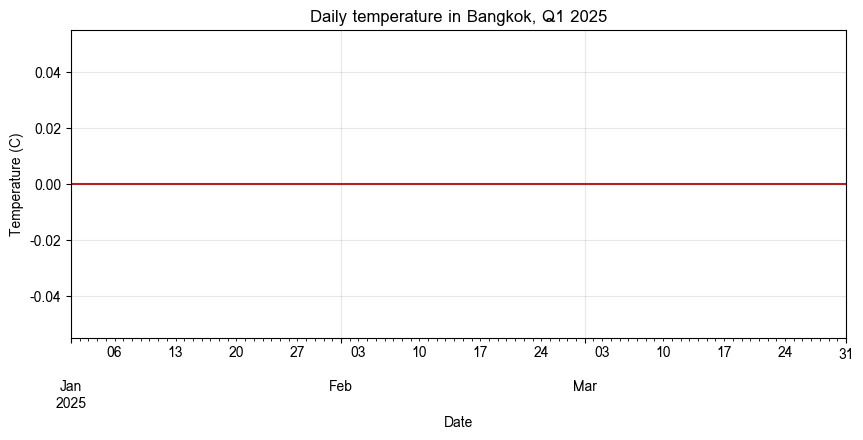

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

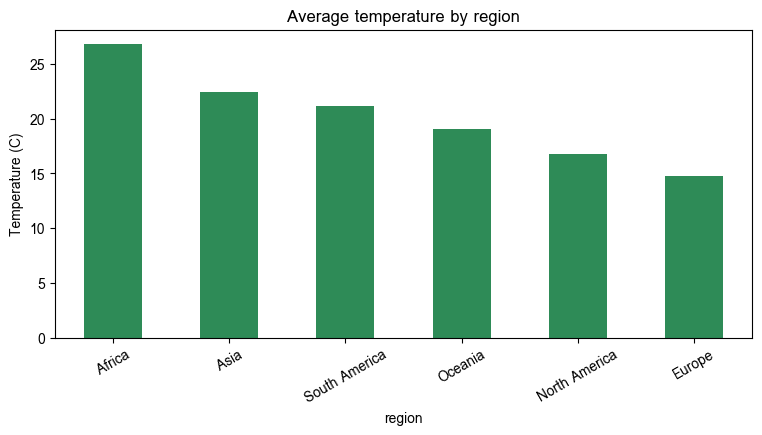

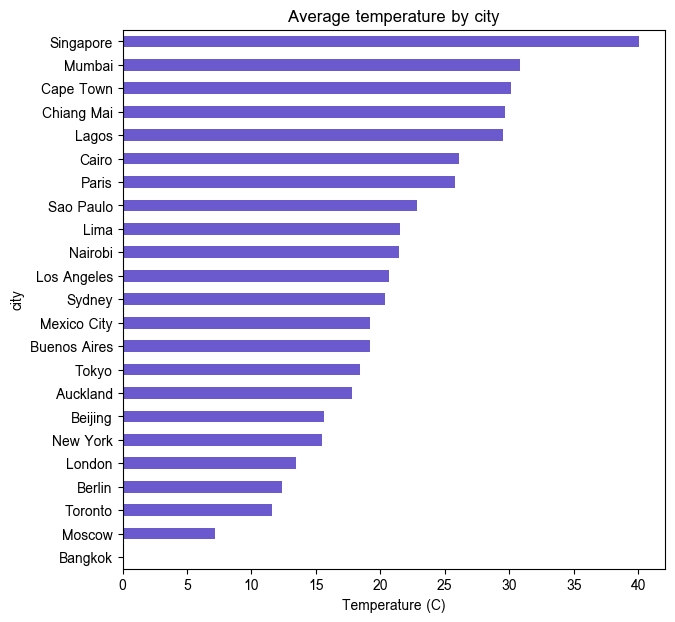

In [100]:
avg_by_region = df.groupby("region")["temperature_c"].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

avg_by_city = df.groupby("city")["temperature_c"].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

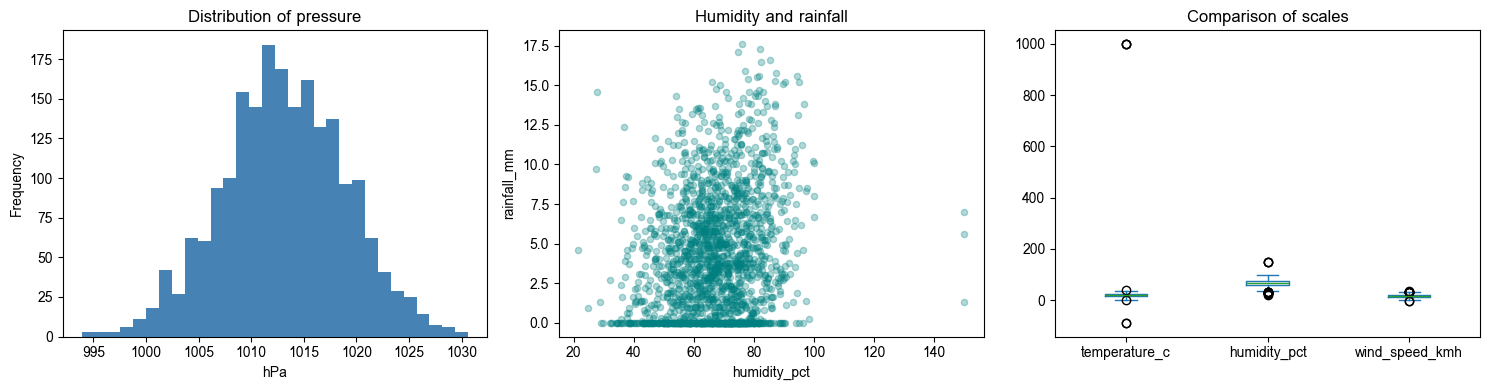

In [101]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["pressure_hpa"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of pressure")
axes[0].set_xlabel("hPa")

df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

df[["temperature_c", "humidity_pct", "wind_speed_kmh"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

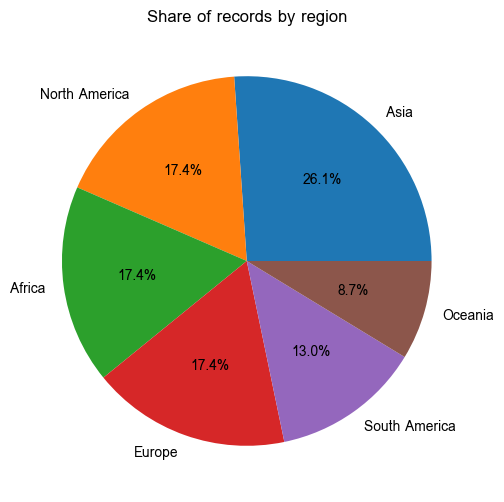

In [102]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

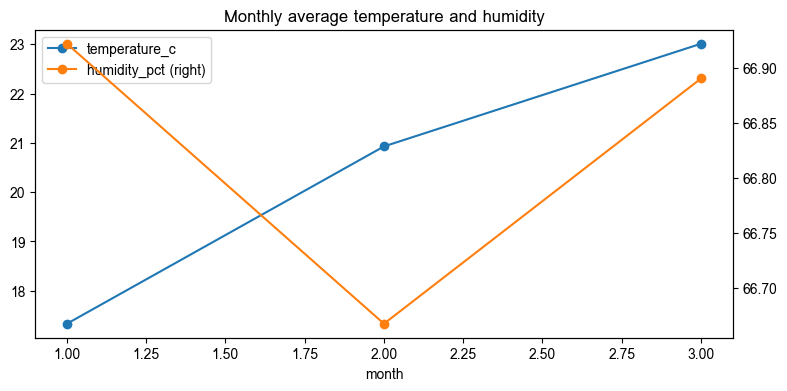

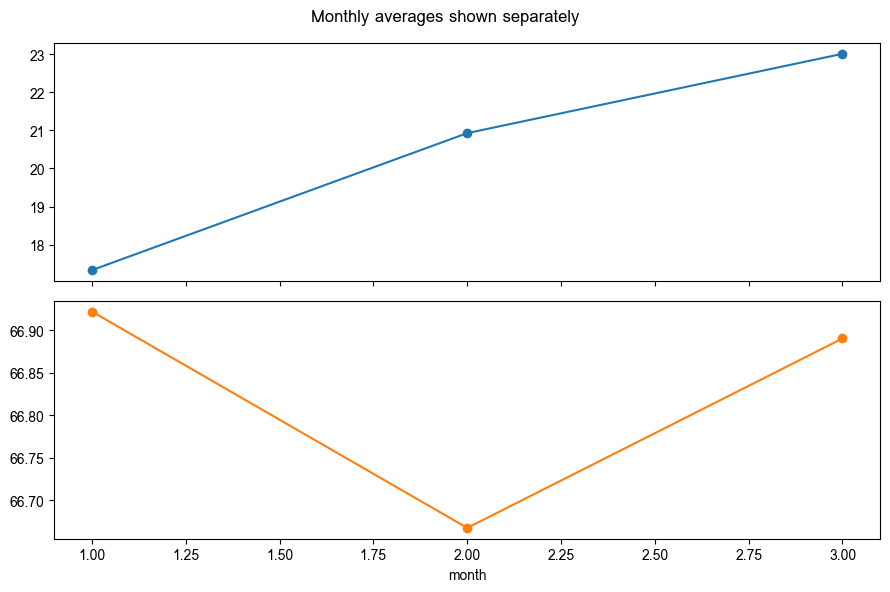

In [103]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

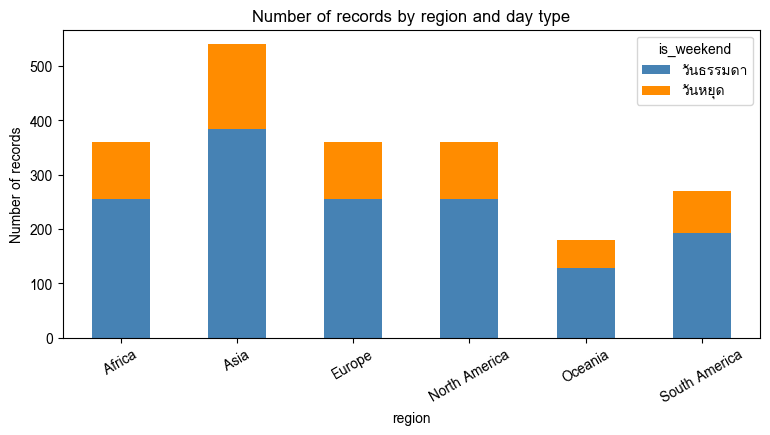

In [104]:
df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (df.groupby(["region", "is_weekend"]).size()
                       .unstack(fill_value=0)
                       .rename(columns={False: "วันธรรมดา", True: "วันหยุด"}))

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"])
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

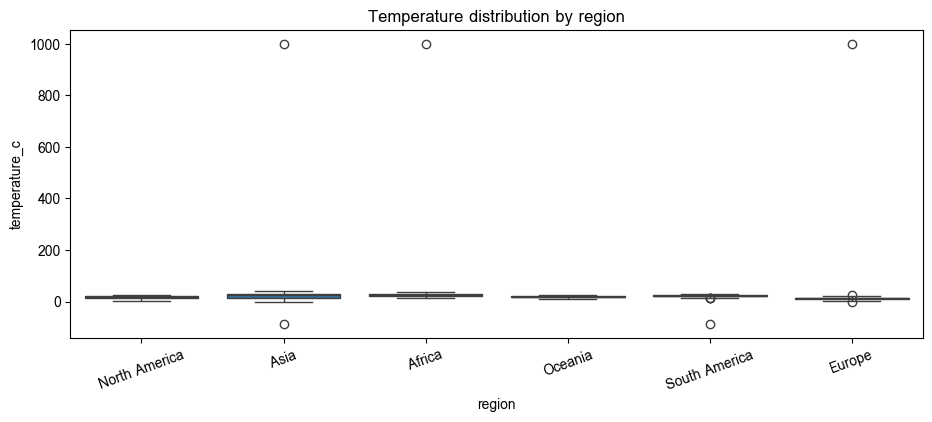

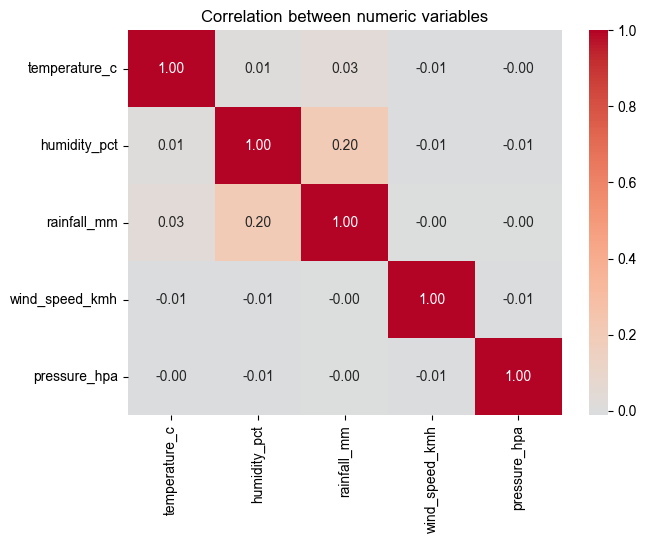

In [105]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

numeric_cols = ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"]
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

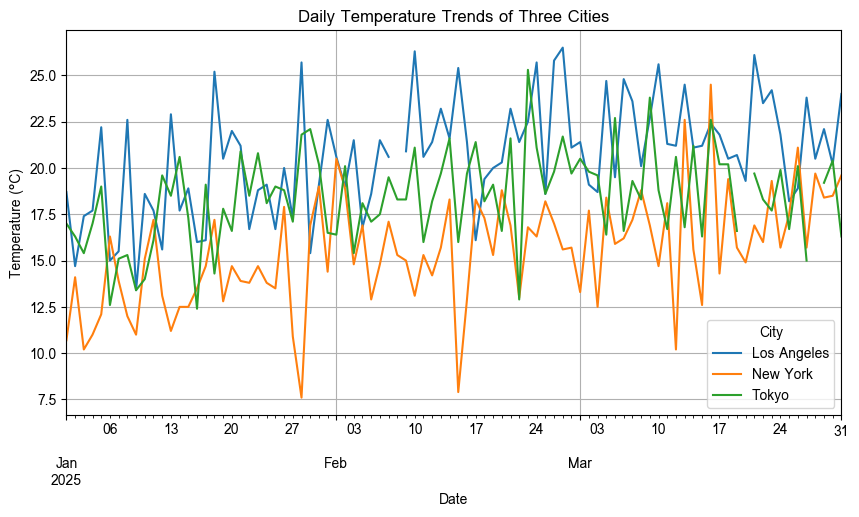

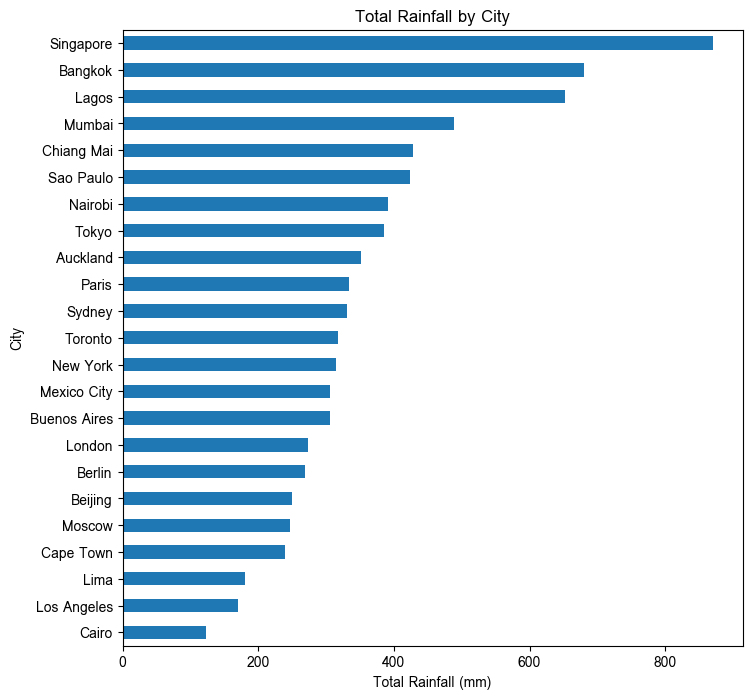

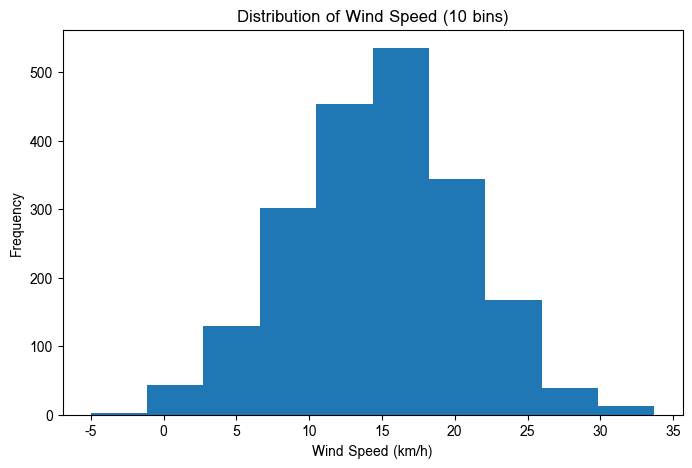

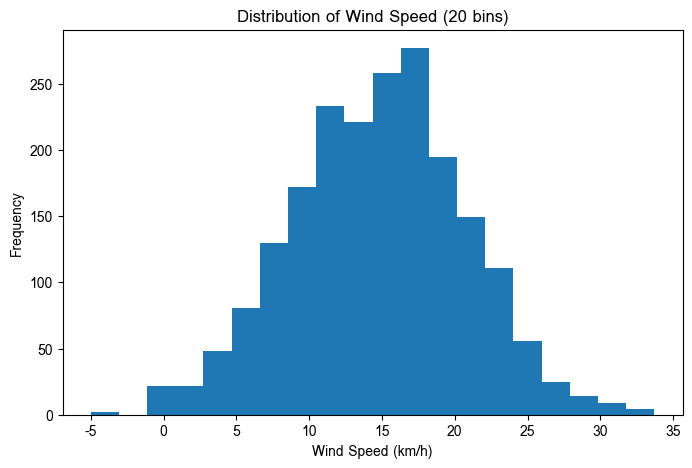

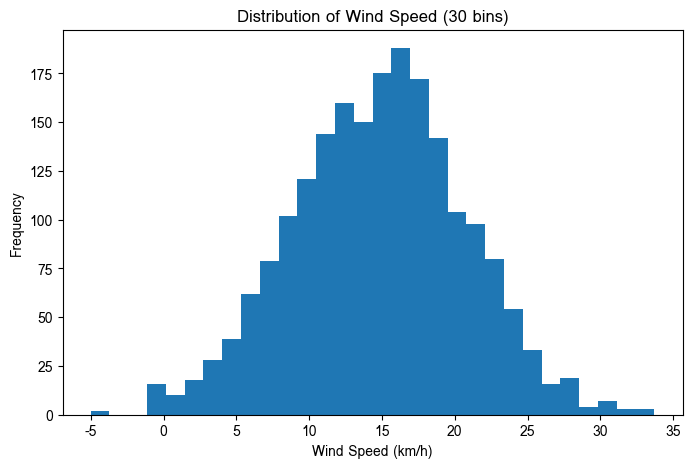

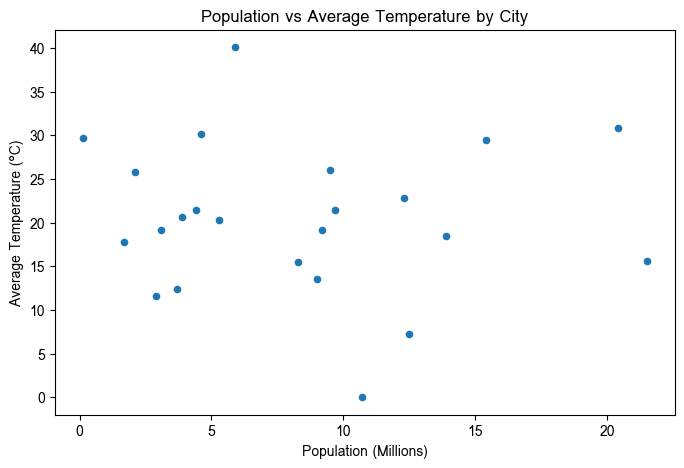

In [106]:
# คำตอบข้อ 17.1
import pandas as pd
import matplotlib.pyplot as plt

# เตรียม date
df["date"] = pd.to_datetime(df["date"])

# 1. กราฟเส้น: อุณหภูมิรายวันของ 3 เมือง
cities = df["city"].unique()[:3]

temp_3cities = (
    df[df["city"].isin(cities)]
    .pivot(index="date", columns="city", values="temperature_c")
)

temp_3cities.plot(figsize=(10, 5))

plt.title("Daily Temperature Trends of Three Cities")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend(title="City")
plt.grid(True)
plt.show()

# 2. กราฟแท่งแนวนอน: ปริมาณฝนรวมรายเมือง
rain_city = (
    df.groupby("city")["rainfall_mm"]
      .sum()
      .sort_values(ascending=True)
)

rain_city.plot(
    kind="barh",
    figsize=(8, 8)
)

plt.title("Total Rainfall by City")
plt.xlabel("Total Rainfall (mm)")
plt.ylabel("City")
plt.show()

# 3. Histogram: wind_speed_kmh ทดลอง bins 3 ค่า
for bins in [10, 20, 30]:
    plt.figure(figsize=(8, 5))
    df["wind_speed_kmh"].plot(
        kind="hist",
        bins=bins
    )
    plt.title(f"Distribution of Wind Speed ({bins} bins)")
    plt.xlabel("Wind Speed (km/h)")
    plt.ylabel("Frequency")
    plt.show()

# 4. Scatter plot: population กับอุณหภูมิเฉลี่ยรายเมือง (ทำการ Left Join เอาประชากรมาก่อน)
df_with_pop = df.merge(city_info[["city", "population_millions"]], on="city", how="left")

city_summary = (
    df_with_pop.groupby("city")
      .agg(
          population_millions=("population_millions", "first"),
          avg_temperature=("temperature_c", "mean")
      )
)

city_summary.plot(
    kind="scatter",
    x="population_millions",
    y="avg_temperature",
    figsize=(8, 5)
)

plt.title("Population vs Average Temperature by City")
plt.xlabel("Population (Millions)")
plt.ylabel("Average Temperature (°C)")
plt.show()

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

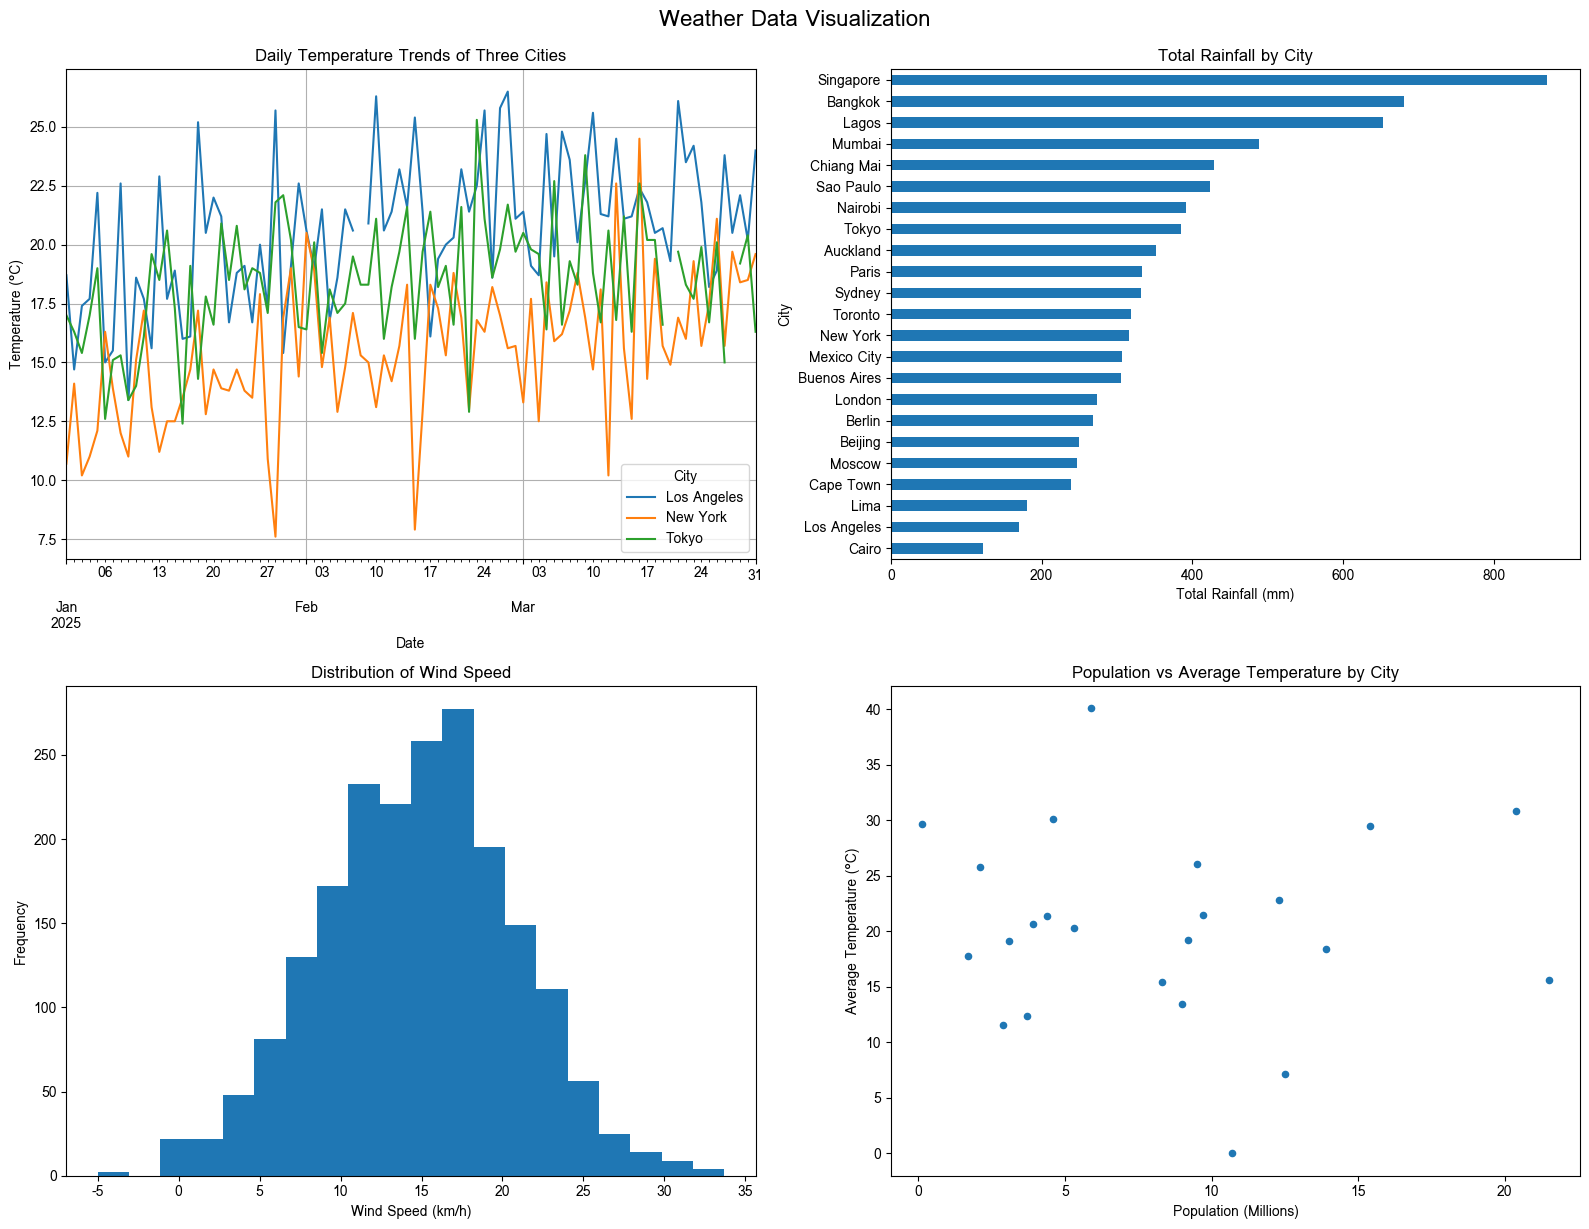

In [107]:
# คำตอบข้อ 17.2
import pandas as pd
import matplotlib.pyplot as plt

df["date"] = pd.to_datetime(df["date"])

# สร้างพื้นที่กราฟ 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Line plot: อุณหภูมิ 3 เมือง
cities = df["city"].unique()[:3]

temp_3cities = (
    df[df["city"].isin(cities)]
    .pivot(index="date", columns="city", values="temperature_c")
)

temp_3cities.plot(ax=axes[0, 0])

axes[0, 0].set_title("Daily Temperature Trends of Three Cities")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Temperature (°C)")
axes[0, 0].legend(title="City")
axes[0, 0].grid(True)

# 2. Horizontal bar: ปริมาณฝนรวมรายเมือง
rain_city = (
    df.groupby("city")["rainfall_mm"]
      .sum()
      .sort_values(ascending=True)
)

rain_city.plot(
    kind="barh",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Total Rainfall by City")
axes[0, 1].set_xlabel("Total Rainfall (mm)")
axes[0, 1].set_ylabel("City")

# 3. Histogram: ความเร็วลม
df["wind_speed_kmh"].plot(
    kind="hist",
    bins=20,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Distribution of Wind Speed")
axes[1, 0].set_xlabel("Wind Speed (km/h)")
axes[1, 0].set_ylabel("Frequency")

# 4. Scatter: Population vs Temperature
df_with_pop = df.merge(
    city_info[["city", "population_millions"]],
    on="city",
    how="left"
)

city_summary = (
    df_with_pop.groupby("city")
    .agg(
        population_millions=("population_millions", "first"),
        avg_temperature=("temperature_c", "mean")
    )
)

city_summary.plot(
    kind="scatter",
    x="population_millions",
    y="avg_temperature",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Population vs Average Temperature by City")
axes[1, 1].set_xlabel("Population (Millions)")
axes[1, 1].set_ylabel("Average Temperature (°C)")

# ปรับระยะห่างและกำหนดชื่อรวม
plt.tight_layout()

plt.suptitle(
    "Weather Data Visualization",
    fontsize=16,
    y=1.02
)

plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

=== จำนวนวันในแต่ละช่วงปริมาณฝน จำแนกตามภูมิภาค ===
region      Africa  Asia  Europe  North America  Oceania  South America
rain_range                                                             
0-10 mm        318   436     335            337      163            242
10-30 mm        31    90      15             11        9             21


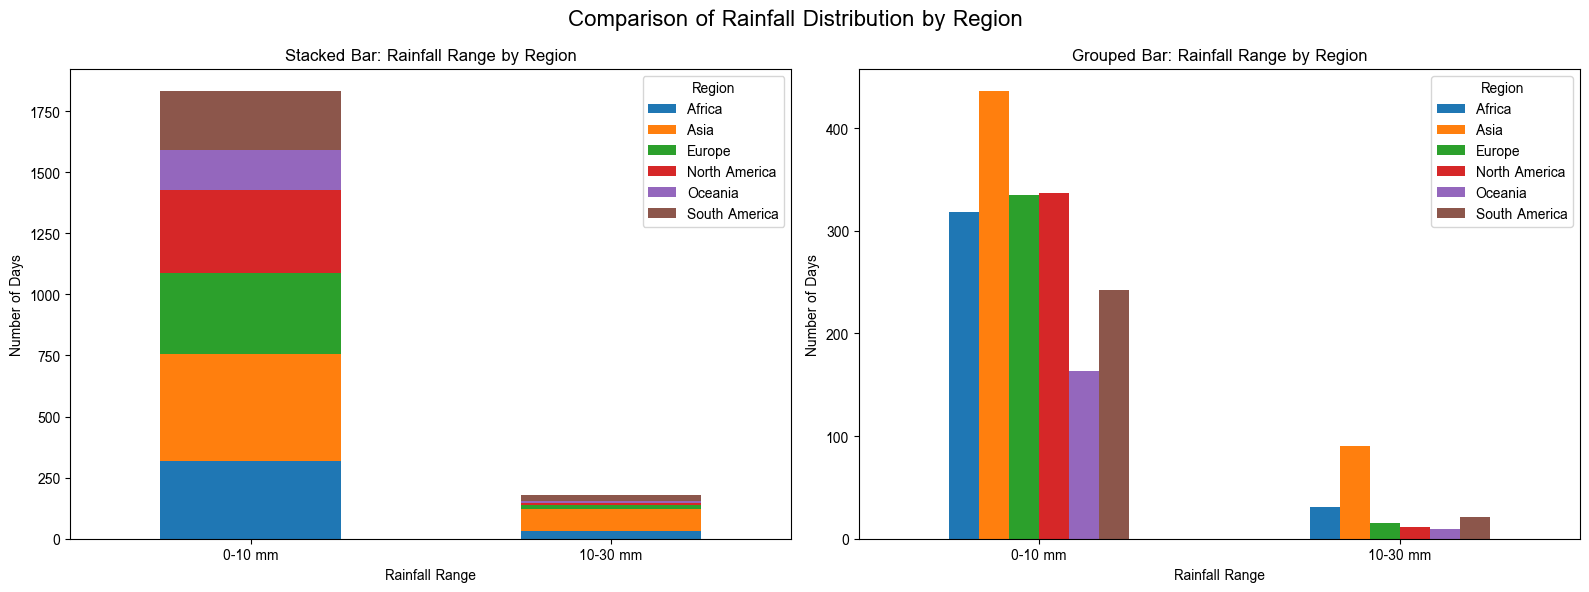

In [108]:
# คำตอบข้อ 17.3
import pandas as pd
import matplotlib.pyplot as plt

# 1. แบ่งช่วงปริมาณฝนด้วย pd.cut()
rain_bins = [0, 10, 30, 60, float("inf")]
rain_labels = [
    "0-10 mm",
    "10-30 mm",
    "30-60 mm",
    ">60 mm"
]

df["rain_range"] = pd.cut(
    df["rainfall_mm"],
    bins=rain_bins,
    labels=rain_labels,
    include_lowest=True
)


# 2. นับจำนวนวันในแต่ละช่วงปริมาณฝน
#    จำแนกตามภูมิภาค
rain_region = pd.crosstab(
    df["rain_range"],
    df["region"]
)

print("=== จำนวนวันในแต่ละช่วงปริมาณฝน จำแนกตามภูมิภาค ===")
print(rain_region)

# 3. สร้างกราฟ 2 แบบเพื่อเปรียบเทียบ
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------
# กราฟที่ 1: Stacked Bar
# ------------------------------------------
rain_region.plot(
    kind="bar",
    stacked=True,
    ax=axes[0]
)

axes[0].set_title("Stacked Bar: Rainfall Range by Region")
axes[0].set_xlabel("Rainfall Range")
axes[0].set_ylabel("Number of Days")
axes[0].legend(title="Region")
axes[0].tick_params(axis="x", rotation=0)

# ------------------------------------------
# กราฟที่ 2: Grouped Bar
# stacked=False
# ------------------------------------------
rain_region.plot(
    kind="bar",
    stacked=False,
    ax=axes[1]
)

axes[1].set_title("Grouped Bar: Rainfall Range by Region")
axes[1].set_xlabel("Rainfall Range")
axes[1].set_ylabel("Number of Days")
axes[1].legend(title="Region")
axes[1].tick_params(axis="x", rotation=0)

# ชื่อรวม
plt.suptitle(
    "Comparison of Rainfall Distribution by Region",
    fontsize=16
)

plt.tight_layout()
plt.show()

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

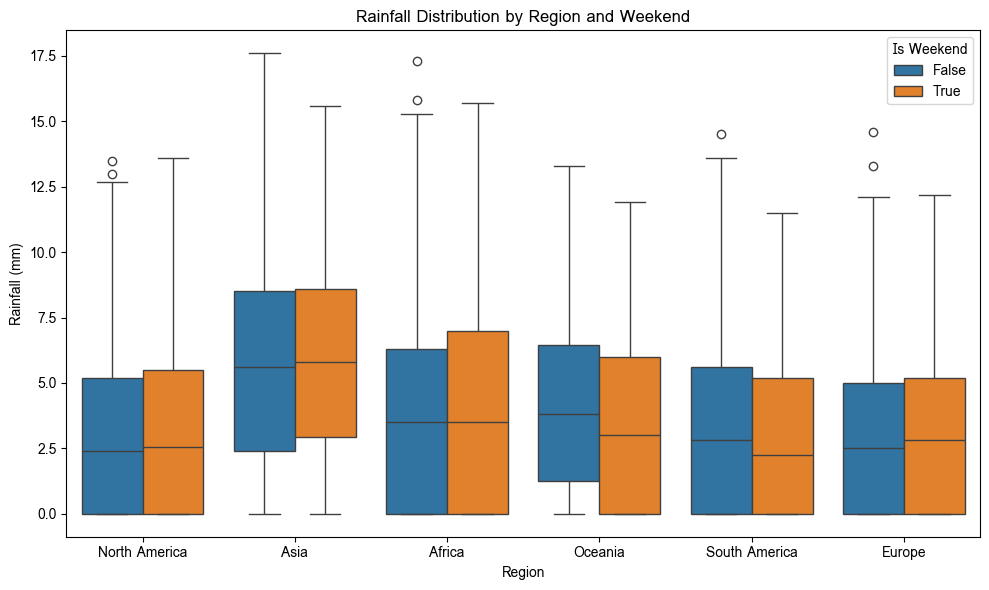

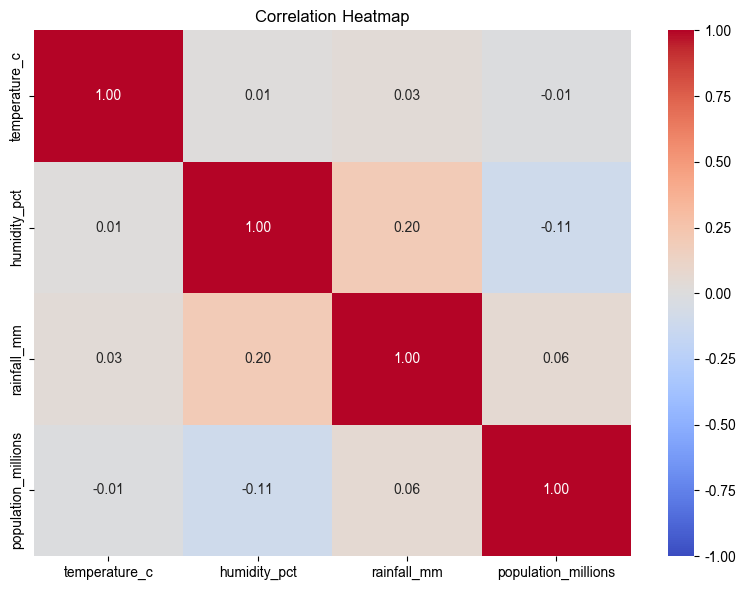

=== Correlation Matrix ===
                     temperature_c  humidity_pct  rainfall_mm  \
temperature_c             1.000000      0.011484     0.032908   
humidity_pct              0.011484      1.000000     0.198903   
rainfall_mm               0.032908      0.198903     1.000000   
population_millions      -0.013440     -0.106284     0.061099   

                     population_millions  
temperature_c                  -0.013440  
humidity_pct                   -0.106284  
rainfall_mm                     0.061099  
population_millions             1.000000  


In [109]:
# คำตอบข้อ 17.4
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# เตรียมข้อมูล
df["date"] = pd.to_datetime(df["date"])

# สร้าง is_weekend จากวัน
df["is_weekend"] = df["date"].dt.dayofweek >= 5

# นำ population_millions จาก city_info มาเชื่อมกับ df
df_seaborn = df.merge(
    city_info[["city", "population_millions"]],
    on="city",
    how="left"
)

# 1. Boxplot: Rainfall จำแนกตาม Region
#    และแยกสีตาม is_weekend
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_seaborn,
    x="region",
    y="rainfall_mm",
    hue="is_weekend"
)

plt.title("Rainfall Distribution by Region and Weekend")
plt.xlabel("Region")
plt.ylabel("Rainfall (mm)")
plt.legend(title="Is Weekend")
plt.tight_layout()
plt.show()

# 2. Heatmap: Correlation
corr = df_seaborn[
    [
        "temperature_c",
        "humidity_pct",
        "rainfall_mm",
        "population_millions"
    ]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# แสดงค่าความสัมพันธ์
print("=== Correlation Matrix ===")
print(corr)

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

In [110]:
# คำตอบข้อ 18.1
import pandas as pd

# Q1: มกราคม - มีนาคม
# ใช้เฉพาะข้อมูลที่มี date, region และ temperature_c
q1 = df_clean[
    df_clean["date"].dt.month.isin([1, 2, 3])
].dropna(
    subset=["date", "region", "city", "temperature_c"]
)

# คำนวณ SD ระดับภูมิภาคและระดับเมือง
result = (
    q1.groupby(["region", "city"])["temperature_c"]
      .agg(city_sd="std", city_days="count")
      .reset_index()
)

result["region_sd"] = (
    result.groupby("region")["city_sd"]
    .transform("std")
)

# หา SD อุณหภูมิจริงของแต่ละภูมิภาค
region_sd = (
    q1.groupby("region")["temperature_c"]
      .std()
      .rename("region_sd")
)

result = result.drop(columns="region_sd").merge(
    region_sd,
    on="region",
    how="left"
)

# เรียงภูมิภาคที่มี SD สูงสุดไว้ก่อน
result = result.sort_values(
    ["region_sd", "city_sd"],
    ascending=[False, False]
).reset_index(drop=True)

print(" SD อุณหภูมิรายวันในไตรมาส 1 ")
print(result.to_string(index=False))


 SD อุณหภูมิรายวันในไตรมาส 1 
       region         city    city_sd  city_days  region_sd
       Europe        Paris 104.373645         89  52.544961
       Europe       London   3.018131         88  52.544961
       Europe       Moscow   2.877271         89  52.544961
       Europe       Berlin   2.595986         89  52.544961
       Africa    Cape Town 103.899246         89  52.122025
       Africa      Nairobi   2.852798         89  52.122025
       Africa        Lagos   2.838414         87  52.122025
       Africa        Cairo   2.743190         88  52.122025
         Asia    Singapore 103.011324         90  43.985154
         Asia      Beijing   2.874792         89  43.985154
         Asia   Chiang Mai   2.859373         90  43.985154
         Asia       Mumbai   2.544968         90  43.985154
         Asia        Tokyo   2.518006         88  43.985154
         Asia      Bangkok   0.000000         90  43.985154
South America Buenos Aires  11.817985         89   7.356485
South Amer

2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

In [111]:
# คำตอบข้อ 18.2
import pandas as pd

# กำหนดฝนตกหนัก > 10 mm
result = (
    df_clean.groupby("city")["rainfall_mm"]
    .agg(
        data_days="count",
        heavy_rain_days=lambda x: (x > 10).sum()
    )
    .reset_index()
)

# คำนวณสัดส่วนวันฝนตกหนัก
result["heavy_rain_ratio"] = (
    result["heavy_rain_days"] / result["data_days"]
)

result["heavy_rain_percent"] = (
    result["heavy_rain_ratio"] * 100
)

# อันดับจาก "สัดส่วน"
top5_ratio = (
    result.sort_values(
        "heavy_rain_ratio",
        ascending=False
    )
    .head(5)
    .copy()
)

top5_ratio["rank_by_ratio"] = range(1, 6)

# อันดับจาก "จำนวนวัน"
top5_count = (
    result.sort_values(
        "heavy_rain_days",
        ascending=False
    )
    .head(5)
    .copy()
)

top5_count["rank_by_count"] = range(1, 6)

# รวมผลเพื่อเปรียบเทียบ
comparison = pd.merge(
    top5_ratio[
        [
            "city",
            "data_days",
            "heavy_rain_days",
            "heavy_rain_percent",
            "rank_by_ratio"
        ]
    ],
    top5_count[
        [
            "city",
            "heavy_rain_days",
            "rank_by_count"
        ]
    ],
    on="city",
    how="outer",
    suffixes=("_ratio", "_count")
)

comparison = comparison[
    [
        "city",
        "data_days",
        "heavy_rain_days_ratio",
        "heavy_rain_percent",
        "rank_by_ratio",
        "rank_by_count"
    ]
].sort_values(
    "rank_by_ratio",
    na_position="last"
)

print(" เปรียบเทียบ Top 5: สัดส่วน vs จำนวนวัน ")
print(comparison.to_string(index=False))

 เปรียบเทียบ Top 5: สัดส่วน vs จำนวนวัน 
      city  data_days  heavy_rain_days_ratio  heavy_rain_percent  rank_by_ratio  rank_by_count
 Singapore         90                     44           48.888889              1              1
   Bangkok         87                     23           26.436782              2              2
     Lagos         88                     22           25.000000              3              3
 Sao Paulo         88                     11           12.500000              4              4
Chiang Mai         85                      9           10.588235              5              5


3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

In [112]:
# คำตอบข้อ 18.3
import pandas as pd

# รวม population เข้ากับข้อมูลสภาพอากาศ
city_summary = (
    df_clean
    .merge(
        city_info[["city", "population_millions"]],
        on="city",
        how="left"
    )
    .groupby("city")
    .agg(
        population_millions=("population_millions", "first"),
        avg_temperature=("temperature_c", "mean"),
        avg_rainfall=("rainfall_mm", "mean")
    )
    .dropna()
)

# คำนวณ Pearson correlation
correlation = city_summary[
    ["population_millions", "avg_temperature", "avg_rainfall"]
].corr()["population_millions"].drop("population_millions")

print(" ความสัมพันธ์ระหว่างประชากรกับสภาพอากาศ ")
print(correlation.to_frame("pearson_correlation"))

print("\n ข้อมูลระดับเมืองที่ใช้วิเคราะห์ ")
print(city_summary)

 ความสัมพันธ์ระหว่างประชากรกับสภาพอากาศ 
                 pearson_correlation
avg_temperature            -0.058719
avg_rainfall                0.122623

 ข้อมูลระดับเมืองที่ใช้วิเคราะห์ 
              population_millions  avg_temperature  avg_rainfall
city                                                            
Auckland                     1.70        17.804444      4.140000
Bangkok                     10.70         0.000000      7.816092
Beijing                     21.50        15.598876      2.842045
Berlin                       3.70        12.383146      3.085057
Buenos Aires                 3.10        19.171910      3.467045
Cairo                        9.50        26.070455      1.406897
Cape Town                    4.60        30.162921      2.750575
Chiang Mai                   0.13        29.650000      5.036471
Lagos                       15.40        29.494253      7.418182
Lima                         9.70        21.490000      2.072414
London                       9.00

4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

In [113]:
# คำตอบข้อ 18.4
import pandas as pd

q4 = df_clean.copy()
q4["month"] = q4["date"].dt.month

result = (
    q4.groupby(["region", "month"])["rainfall_mm"]
      .agg(
          data_days="count",
          heavy_rain_days=lambda x: (x > 10).sum()
      )
      .reset_index()
)

result["heavy_rain_ratio"] = (
    result["heavy_rain_days"] / result["data_days"]
)

result["heavy_rain_percent"] = (
    result["heavy_rain_ratio"] * 100
)

# หาเดือนที่มีสัดส่วนวันฝนตกหนักสูงสุดของแต่ละภูมิภาค
result["rank"] = (
    result.groupby("region")["heavy_rain_ratio"]
          .rank(method="first", ascending=False)
)

result = (
    result[result["rank"] == 1]
    [
        [
            "region",
            "month",
            "data_days",
            "heavy_rain_days",
            "heavy_rain_percent"
        ]
    ]
    .sort_values("region")
    .reset_index(drop=True)
)

result["month"] = result["month"].map({
    1: "มกราคม", 2: "กุมภาพันธ์", 3: "มีนาคม",
    4: "เมษายน", 5: "พฤษภาคม", 6: "มิถุนายน",
    7: "กรกฎาคม", 8: "สิงหาคม", 9: "กันยายน",
    10: "ตุลาคม", 11: "พฤศจิกายน", 12: "ธันวาคม"
})

print("เดือนที่ควรหลีกเลี่ยงการเดินทางของแต่ละภูมิภาค")
print(result.to_string(index=False))

เดือนที่ควรหลีกเลี่ยงการเดินทางของแต่ละภูมิภาค
       region      month  data_days  heavy_rain_days  heavy_rain_percent
       Africa     มกราคม        120               12           10.000000
         Asia กุมภาพันธ์        163               38           23.312883
       Europe     มีนาคม        121                7            5.785124
North America กุมภาพันธ์        109                4            3.669725
      Oceania     มีนาคม         55                6           10.909091
South America     มกราคม         91                8            8.791209


---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️